In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARY
# File: 02_image_main.ipynb
# Deskripsi: Import seluruh library yang dibutuhkan untuk
#            pipeline analisis dataset citra MRI MS
# ============================================================

# --- Library standar Python ---
import os                    # Navigasi folder dan path file
import warnings
warnings.filterwarnings('ignore')

# --- Manipulasi data ---
import numpy as np           # Operasi array dan matriks
import pandas as pd          # Manipulasi DataFrame dan file Excel

# --- Library khusus MRI (berbeda dari pipeline tabular) ---
import nibabel as nib        # Membaca file .nii (format NIfTI)
from scipy import ndimage    # Menghitung connected components lesi

# --- Preprocessing & resampling ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

# --- Handling class imbalance ---
from imblearn.over_sampling import SMOTE

# --- Algoritma model (identik dengan pipeline tabular) ---
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

# --- Visualisasi ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# --- Konfigurasi tampilan ---
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

# --- Verifikasi versi library kritis ---
print("=" * 55)
print("   VERIFIKASI LIBRARY — 02_image_main.ipynb")
print("=" * 55)
print(f"  numpy         : {np.__version__}")
print(f"  pandas        : {pd.__version__}")
print(f"  nibabel       : {nib.__version__}")

import sklearn
print(f"  scikit-learn  : {sklearn.__version__}")

import xgboost
print(f"  xgboost       : {xgboost.__version__}")

import imblearn
print(f"  imbalanced    : {imblearn.__version__}")

import matplotlib
print(f"  matplotlib    : {matplotlib.__version__}")
print(f"  seaborn       : {sns.__version__}")
print("=" * 55)
print("  Semua library berhasil diimport!")
print("=" * 55)

   VERIFIKASI LIBRARY — 02_image_main.ipynb
  numpy         : 2.3.1
  pandas        : 2.3.1
  nibabel       : 5.4.2
  scikit-learn  : 1.7.1
  xgboost       : 3.0.1
  imbalanced    : 0.14.1
  matplotlib    : 3.10.0
  seaborn       : 0.13.2
  Semua library berhasil diimport!


In [2]:
# ============================================================
# CELL 2 — LOAD FILE EXCEL
# Deskripsi: Membaca patient_info.xlsx dan
#            sequence_parameters.xlsx dengan header=1
#            untuk skip baris keterangan merged cell
# ============================================================

# --- Definisi path utama dataset ---
BASE_PATH         = r"Dataset_Citra"
PATIENT_INFO_PATH = os.path.join(BASE_PATH, "Supplementary Table 1 for patient info.xlsx")
SEQ_PARAMS_PATH   = os.path.join(BASE_PATH, "Supplementary Table 2 for  sequence parameters.xlsx")
NII_FOLDER        = BASE_PATH

# --- Validasi path ---
print("=" * 55)
#print("   VALIDASI PATH DATASET")
#print("=" * 55)
#for label, path in [("BASE_PATH         ", BASE_PATH),
#                    ("Supplementary Table 1 for patient info.xlsx", PATIENT_INFO_PATH),
#                    ("Supplementary Table 2 for  sequence parameters.xlsx", SEQ_PARAMS_PATH)]:
#    status = "DITEMUKAN" if os.path.exists(path) else "TIDAK DITEMUKAN"
#    print(f"  {label}: {status}")
#print("=" * 55)

# --- Load patient_info.xlsx ---
# header=1 → skip baris 0 (keterangan merged cell),
#             gunakan baris 1 sebagai nama kolom
df_patient = pd.read_excel(PATIENT_INFO_PATH, header=1)

# Bersihkan spasi tersembunyi di nama kolom jika ada
df_patient.columns = df_patient.columns.str.strip()

print("\n[1] PATIENT INFO — Shape:", df_patient.shape)
print("    Expected : (60, 29)")
status_shape = "✓ SESUAI" if df_patient.shape == (60, 29) else "✗ PERIKSA ULANG"
print(f"    Status   : {status_shape}")

print("\n[2] PATIENT INFO — Nama Kolom:")
print("-" * 55)
for i, col in enumerate(df_patient.columns.tolist(), 1):
    print(f"  {i:02d}. {col}")

print("\n[3] PATIENT INFO — 3 Baris Pertama Data:")
print("-" * 55)
print(df_patient.head(3).to_string())

print("\n[4] PATIENT INFO — Tipe Data per Kolom:")
print("-" * 55)
print(df_patient.dtypes)

print("\n[5] PATIENT INFO — Statistik Deskriptif (kolom numerik):")
print("-" * 55)
print(df_patient.describe())

# --- Cek kolom EDSS khusus ---
print("\n[6] CEK KOLOM EDSS:")
print("-" * 55)
print(f"  Tipe data EDSS : {df_patient['EDSS'].dtype}")
print(f"  Nilai min      : {df_patient['EDSS'].min()}")
print(f"  Nilai max      : {df_patient['EDSS'].max()}")
print(f"  Missing values : {df_patient['EDSS'].isnull().sum()}")
print(f"  Nilai unik     : {sorted(df_patient['EDSS'].unique().tolist())}")

# --- Load sequence_parameters.xlsx ---
# Sama seperti file pertama kalau header=0 akan mengambil kolom atas, karena itu memakai header=1
df_seq = pd.read_excel(SEQ_PARAMS_PATH, header=1)
df_seq.columns = df_seq.columns.str.strip()

print("\n[7] SEQUENCE PARAMETERS — Shape:", df_seq.shape)
print("-" * 55)
print(df_seq.head())

print("\n[8] SEQUENCE PARAMETERS — Nama Kolom:")
print("-" * 55)
for i, col in enumerate(df_seq.columns.tolist(), 1):
    print(f"  {i:02d}. {col}")

# --- Cek missing values kedua file ---
print("\n[9] MISSING VALUES — patient_info.xlsx:")
print("-" * 55)
mv_patient = df_patient.isnull().sum()
mv_patient = mv_patient[mv_patient > 0]
print("  Tidak ada missing values." if len(mv_patient) == 0 else mv_patient)

print("\n[10] MISSING VALUES — sequence_parameters.xlsx:")
print("-" * 55)
mv_seq = df_seq.isnull().sum()
mv_seq = mv_seq[mv_seq > 0]
print("  Tidak ada missing values." if len(mv_seq) == 0 else mv_seq)

# --- Validasi jumlah folder patient ---
print("\n[11] VALIDASI KONSISTENSI DATA:")
print("-" * 55)
n_patient_excel = len(df_patient)
n_folders = len([
    f for f in os.listdir(NII_FOLDER)
    if os.path.isdir(os.path.join(NII_FOLDER, f))
    and f.lower().startswith('patient-')
])
print(f"  Jumlah baris patient_info.xlsx : {n_patient_excel}")
print(f"  Jumlah folder Patient-N        : {n_folders}")

if n_patient_excel == n_folders == 60:
    print("  Status: ✓ KONSISTEN — 60 pasien terdeteksi di kedua sumber.")
elif n_patient_excel == n_folders:
    print(f"  Status: ✓ KONSISTEN — {n_patient_excel} pasien terdeteksi.")
else:
    print("  Status: ✗ TIDAK KONSISTEN — periksa nama folder atau file Excel!")

print("\n  Cell 2 selesai. Lanjut ke Cell 3 — EDA.")


[1] PATIENT INFO — Shape: (60, 29)
    Expected : (60, 29)
    Status   : ✓ SESUAI

[2] PATIENT INFO — Nama Kolom:
-------------------------------------------------------
  01. ID
  02. Gender
  03. Age
  04. Age of onset
  05. EDSS
  06. Does the time difference between MRI acquisition and EDSS < two months
  07. Types of Medicines
  08. Presenting Symptom
  09. Dose the patient has Co-moroidity
  10. Pyramidal
  11. Cerebella
  12. Brain stem
  13. Sensory
  14. Sphincters
  15. Visual
  16. Mental
  17. Speech
  18. Motor System
  19. Sensory System
  20. Coordination
  21. Gait
  22. Bowel and bladder function
  23. Mobility
  24. Mental State
  25. Optic discs
  26. Fields
  27. Nystagmus
  28. Ocular Movement
  29. Swallowing

[3] PATIENT INFO — 3 Baris Pertama Data:
-------------------------------------------------------
   ID Gender  Age  Age of onset   EDSS Does the time difference between MRI acquisition and EDSS < two months Types of Medicines Presenting Symptom Dose the pa

   Section 1 — Ringkasan Umum Dataset

  Total pasien        : 60
  Total fitur         : 29
  Missing values      : 0
  Kolom demografis    : ID, Gender, Age, Age of onset
  Kolom klinis        : EDSS, Types of Medicines, dll
  Kolom neurologis    : 20 kolom (biner 0/1)


   Section 2 — Distribusi EDSS
EDSS
0.0000     5
0.5000     4
1.0000    13
1.5000     7
2.0000     4
2.5000     2
3.0000     8
3.5000     4
4.0000     7
4.5000     1
5.0000     3
6.0000     2

  Mean EDSS   : 2.2667
  Median EDSS : 2.0000
  Std EDSS    : 1.5957

  Simulasi distribusi label (cutoff EDSS = 3):
  Label 0 — Mild (EDSS < 3)             : 35 pasien (58.3%)
  Label 1 — Moderate-Severe (EDSS >= 3) : 25 pasien (41.7%)


   Section 3 — Distribusi Demografis
  Gender : {'F': 46, 'M': 13, 'N': 1}
  Usia   : min=15, max=56, mean=32.6
  Onset  : min=8, max=52, mean=29.8


   Section 4 — Prevalensi Abnormalitas Neurologis
  Motor System                : 0.58 ███████████
  Pyramidal                   : 0.52 ████████

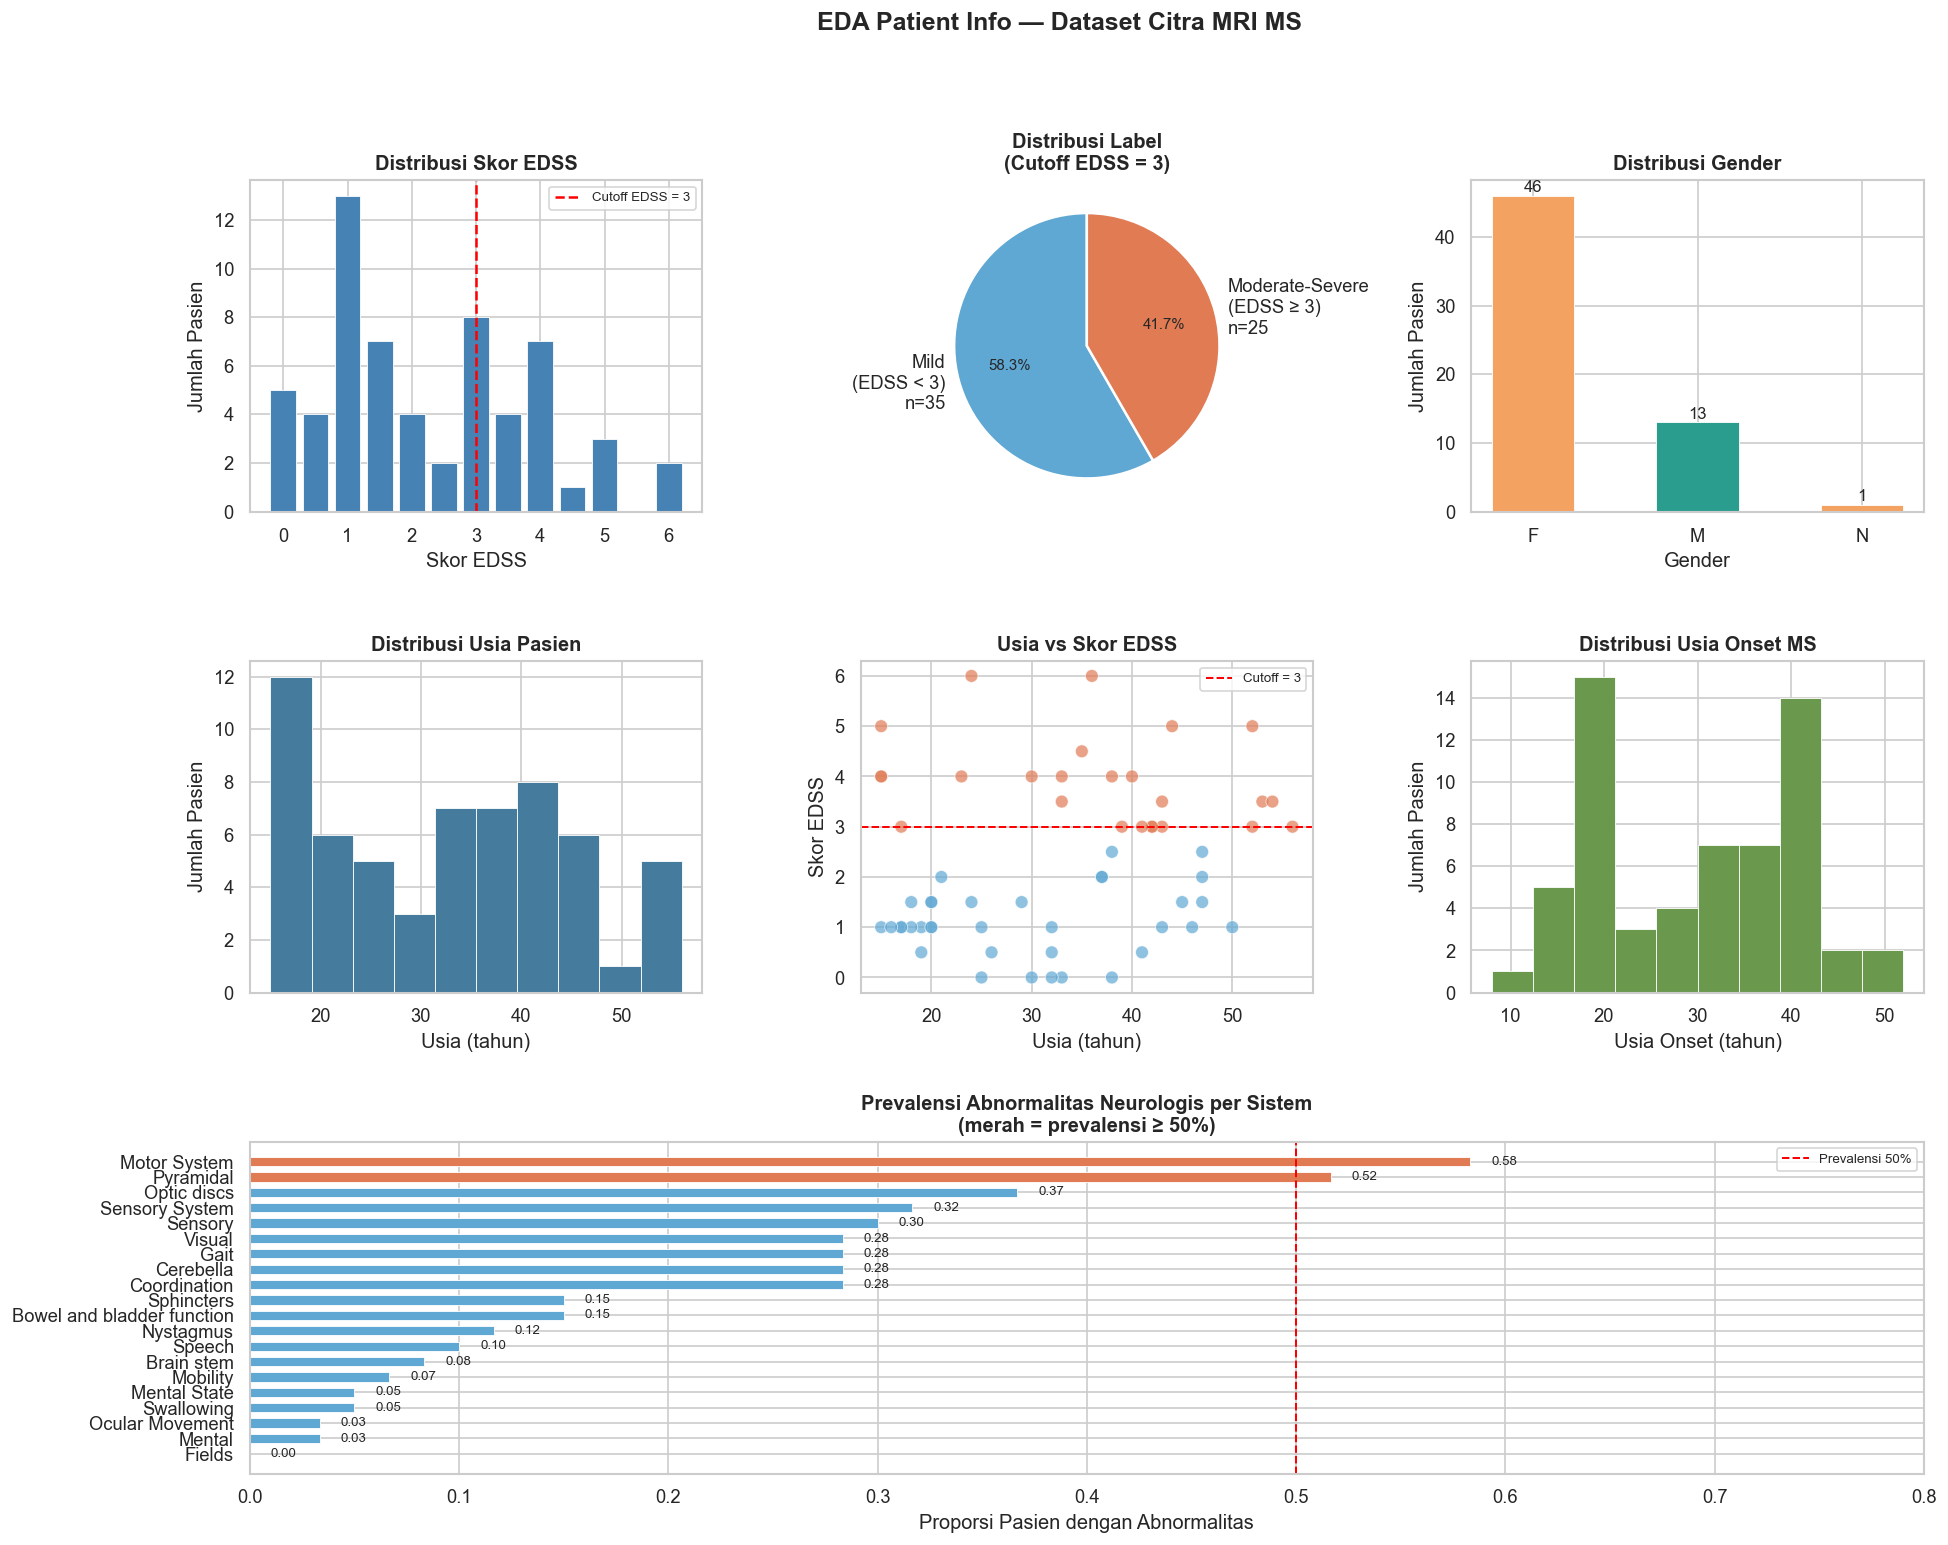

  Visualisasi tersimpan: eda_patient_info.png

  Cell 3 selesai. Lanjut ke Cell 4 — Load & Validasi .nii


In [3]:
# ============================================================
# CELL 3 — EXPLORATORY DATA ANALYSIS (EDA) PATIENT INFO
# Deskripsi: Analisis distribusi EDSS, demografi pasien,
#            dan pola abnormalitas neurologis
# ============================================================

# ── Section 1 — Ringkasan Umum Dataset ──────────────────────
print("=" * 55)
print("   Section 1 — Ringkasan Umum Dataset")
print("=" * 55)
print(f"\n  Total pasien        : {len(df_patient)}")
print(f"  Total fitur         : {df_patient.shape[1]}")
print(f"  Missing values      : {df_patient.isnull().sum().sum()}")

neuro_cols = ['Pyramidal', 'Cerebella', 'Brain stem', 'Sensory',
              'Sphincters', 'Visual', 'Mental', 'Speech',
              'Motor System', 'Sensory System', 'Coordination',
              'Gait', 'Bowel and bladder function', 'Mobility',
              'Mental State', 'Optic discs', 'Fields',
              'Nystagmus', 'Ocular Movement', 'Swallowing']

print(f"  Kolom demografis    : ID, Gender, Age, Age of onset")
print(f"  Kolom klinis        : EDSS, Types of Medicines, dll")
print(f"  Kolom neurologis    : {len(neuro_cols)} kolom (biner 0/1)")

# ── Section 2 — Distribusi EDSS ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Distribusi EDSS")
print("=" * 55)
edss_counts = df_patient['EDSS'].value_counts().sort_index()
print(edss_counts.to_string())
print(f"\n  Mean EDSS   : {df_patient['EDSS'].mean():.4f}")
print(f"  Median EDSS : {df_patient['EDSS'].median():.4f}")
print(f"  Std EDSS    : {df_patient['EDSS'].std():.4f}")

df_patient['Label_Preview'] = (df_patient['EDSS'] >= 3).astype(int)
label_counts = df_patient['Label_Preview'].value_counts()
print(f"\n  Simulasi distribusi label (cutoff EDSS = 3):")
print(f"  Label 0 — Mild (EDSS < 3)             : "
      f"{label_counts.get(0, 0)} pasien "
      f"({label_counts.get(0, 0)/len(df_patient)*100:.1f}%)")
print(f"  Label 1 — Moderate-Severe (EDSS >= 3) : "
      f"{label_counts.get(1, 0)} pasien "
      f"({label_counts.get(1, 0)/len(df_patient)*100:.1f}%)")

# ── Section 3 — Distribusi Demografis ───────────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Distribusi Demografis")
print("=" * 55)
gender_counts = df_patient['Gender'].value_counts()
print(f"  Gender : {gender_counts.to_dict()}")
print(f"  Usia   : min={df_patient['Age'].min()}, "
      f"max={df_patient['Age'].max()}, "
      f"mean={df_patient['Age'].mean():.1f}")
print(f"  Onset  : min={df_patient['Age of onset'].min()}, "
      f"max={df_patient['Age of onset'].max()}, "
      f"mean={df_patient['Age of onset'].mean():.1f}")

# ── Section 4 — Prevalensi Abnormalitas Neurologis ──────────
print("\n")
print("=" * 55)
print("   Section 4 — Prevalensi Abnormalitas Neurologis")
print("=" * 55)
neuro_prevalence = df_patient[neuro_cols].mean().sort_values(ascending=False)
for col, val in neuro_prevalence.items():
    bar = '█' * int(val * 20)
    print(f"  {col:<28}: {val:.2f} {bar}")

# ── Section 5 — Visualisasi EDA ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Visualisasi EDA")
print("=" * 55)

fig = plt.figure(figsize=(18, 14))
fig.suptitle('EDA Patient Info — Dataset Citra MRI MS',
             fontsize=15, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(3, 3, figure=fig,
                       hspace=0.45, wspace=0.35)

# Plot 1 — Distribusi EDSS
ax1 = fig.add_subplot(gs[0, 0])
edss_vals = df_patient['EDSS'].value_counts().sort_index()
ax1.bar(edss_vals.index, edss_vals.values,
        width=0.4, color='steelblue',
        edgecolor='white', linewidth=0.5)
ax1.axvline(x=3, color='red', linestyle='--',
            linewidth=1.5, label='Cutoff EDSS = 3')
ax1.set_title('Distribusi Skor EDSS', fontweight='bold')
ax1.set_xlabel('Skor EDSS')
ax1.set_ylabel('Jumlah Pasien')
ax1.legend(fontsize=8)

# Plot 2 — Distribusi Label
ax2 = fig.add_subplot(gs[0, 1])
label_vals = [label_counts.get(0, 0), label_counts.get(1, 0)]
label_names = [f'Mild\n(EDSS < 3)\nn={label_vals[0]}',
               f'Moderate-Severe\n(EDSS ≥ 3)\nn={label_vals[1]}']
colors_pie = ['#5fa8d3', '#e07b54']
wedges, texts, autotexts = ax2.pie(
    label_vals, labels=label_names, autopct='%1.1f%%',
    colors=colors_pie, startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
for at in autotexts:
    at.set_fontsize(9)
ax2.set_title('Distribusi Label\n(Cutoff EDSS = 3)', fontweight='bold')

# Plot 3 — Distribusi Gender
ax3 = fig.add_subplot(gs[0, 2])
gender_df = df_patient['Gender'].value_counts()
bars = ax3.bar(gender_df.index, gender_df.values,
               color=['#f4a261', '#2a9d8f'],
               edgecolor='white', linewidth=0.5, width=0.5)
for bar, val in zip(bars, gender_df.values):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             str(val), ha='center', fontsize=10)
ax3.set_title('Distribusi Gender', fontweight='bold')
ax3.set_xlabel('Gender')
ax3.set_ylabel('Jumlah Pasien')

# Plot 4 — Distribusi Usia
ax4 = fig.add_subplot(gs[1, 0])
ax4.hist(df_patient['Age'], bins=10, color='#457b9d',
         edgecolor='white', linewidth=0.5)
ax4.set_title('Distribusi Usia Pasien', fontweight='bold')
ax4.set_xlabel('Usia (tahun)')
ax4.set_ylabel('Jumlah Pasien')

# Plot 5 — Usia vs EDSS scatter
ax5 = fig.add_subplot(gs[1, 1])
colors_scatter = df_patient['Label_Preview'].map(
    {0: '#5fa8d3', 1: '#e07b54'})
ax5.scatter(df_patient['Age'], df_patient['EDSS'],
            c=colors_scatter, alpha=0.7,
            edgecolors='white', linewidth=0.5, s=60)
ax5.axhline(y=3, color='red', linestyle='--',
            linewidth=1.2, label='Cutoff = 3')
ax5.set_title('Usia vs Skor EDSS', fontweight='bold')
ax5.set_xlabel('Usia (tahun)')
ax5.set_ylabel('Skor EDSS')
ax5.legend(fontsize=8)

# Plot 6 — Distribusi Age of Onset
ax6 = fig.add_subplot(gs[1, 2])
ax6.hist(df_patient['Age of onset'], bins=10,
         color='#6a994e', edgecolor='white', linewidth=0.5)
ax6.set_title('Distribusi Usia Onset MS', fontweight='bold')
ax6.set_xlabel('Usia Onset (tahun)')
ax6.set_ylabel('Jumlah Pasien')

# Plot 7 — Prevalensi abnormalitas neurologis
ax7 = fig.add_subplot(gs[2, :])
neuro_sorted = neuro_prevalence.sort_values()
colors_neuro = ['#e07b54' if v >= 0.5 else '#5fa8d3'
                for v in neuro_sorted.values]
bars_neuro = ax7.barh(neuro_sorted.index, neuro_sorted.values,
                      color=colors_neuro, edgecolor='white',
                      linewidth=0.5, height=0.6)
ax7.axvline(x=0.5, color='red', linestyle='--',
            linewidth=1.2, label='Prevalensi 50%')
for bar, val in zip(bars_neuro, neuro_sorted.values):
    ax7.text(val + 0.01, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=8)
ax7.set_title('Prevalensi Abnormalitas Neurologis per Sistem\n'
              '(merah = prevalensi ≥ 50%)', fontweight='bold')
ax7.set_xlabel('Proporsi Pasien dengan Abnormalitas')
ax7.set_xlim(0, 0.8)
ax7.legend(fontsize=8)

plt.savefig(os.path.join(BASE_PATH, 'eda_patient_info.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Visualisasi tersimpan: eda_patient_info.png")

# Hapus kolom preview sementara
df_patient.drop(columns=['Label_Preview'], inplace=True)

print("\n  Cell 3 selesai. Lanjut ke Cell 4 — Load & Validasi .nii")

In [4]:
# ============================================================
# CELL 4 — LOAD & VALIDASI FILE .nii
# Deskripsi: Loop 60 pasien, load 6 file .nii per pasien,
#            validasi shape, voxel spacing, dan kelengkapan
# ============================================================

# ── Section 1 — Definisi Nama File per Pasien ───────────────
print("=" * 55)
print("   Section 1 — Definisi Struktur File .nii")
print("=" * 55)

# Perbaikan ejaan: LesionSeg (single s) sesuai nama file asli
FILE_TEMPLATES = {
    'flair'      : '{n}-Flair.nii',
    'mask_flair' : '{n}-LesionSeg-Flair.nii',
    't1'         : '{n}-T1.nii',
    'mask_t1'    : '{n}-LesionSeg-T1.nii',
    't2'         : '{n}-T2.nii',
    'mask_t2'    : '{n}-LesionSeg-T2.nii',
}

print("  Template nama file yang digunakan:")
for key, template in FILE_TEMPLATES.items():
    contoh = template.replace('{n}', '1')
    print(f"  {key:<12} : {contoh}")

# ── Section 2 — Loop Validasi 60 Pasien ─────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Validasi Kelengkapan & Shape File")
print("=" * 55)

validation_records = []
error_list         = []

for i in range(1, 61):
    patient_id  = i
    folder_name = f"Patient-{i}"
    folder_path = os.path.join(NII_FOLDER, folder_name)
    record      = {'patient_id': patient_id, 'folder': folder_name}
    has_error   = False

    if not os.path.exists(folder_path):
        record['status'] = 'ERROR: folder tidak ditemukan'
        error_list.append(record)
        continue

    shapes = {}

    for key, template in FILE_TEMPLATES.items():
        filename = template.replace('{n}', str(i))
        filepath = os.path.join(folder_path, filename)

        if not os.path.exists(filepath):
            record[f'{key}_status'] = 'MISSING'
            has_error = True
            # Tampilkan nama file yang dicari untuk debugging
            print(f"  ✗ Patient-{i} | MISSING: {filename}")
        else:
            try:
                img = nib.load(filepath)
                shapes[key]             = img.shape
                record[f'{key}_shape']  = str(img.shape)
                record[f'{key}_status'] = 'OK'
            except Exception as e:
                record[f'{key}_status'] = f'ERROR: {str(e)}'
                has_error = True
                
    unique_shapes = list(set(str(s) for s in shapes.values()))
    record['shape_consistency'] = (
        'CONSISTENT' if len(unique_shapes) <= 1 else 'INCONSISTENT'
    )
    
    record['status'] = 'ERROR' if has_error else 'OK'
    validation_records.append(record)

    if has_error:
        error_list.append(record)

df_validation = pd.DataFrame(validation_records)
n_ok    = len(df_validation[df_validation['status'] == 'OK'])
n_error = len(df_validation[df_validation['status'] == 'ERROR'])

print(f"\n  Total pasien diproses : {len(validation_records)}")
print(f"  Status OK             : {n_ok} pasien")
print(f"  Status ERROR          : {n_error} pasien")

if n_error == 0:
    print("\n  ✓ Semua file .nii lengkap dan dapat dibaca!")
else:
    print(f"\n  ✗ Ditemukan {n_error} pasien bermasalah.")
    print("  Cek nama file MISSING di atas untuk konfirmasi ejaan.")

# ── Section 3 — Ringkasan Shape & Voxel Spacing ─────────────
print("\n")
print("=" * 55)
print("   Section 3 — Ringkasan Shape & Voxel Spacing")
print("=" * 55)

print("  Preview shape file .nii (3 pasien pertama):\n")
for i in [1, 2, 3]:
    folder_path = os.path.join(NII_FOLDER, f"Patient-{i}")
    print(f"  Patient-{i}:")
    for key, template in FILE_TEMPLATES.items():
        filename = template.replace('{n}', str(i))
        filepath = os.path.join(folder_path, filename)
        if os.path.exists(filepath):
            img   = nib.load(filepath)
            zooms = img.header.get_zooms()
            print(f"    {key:<12}: shape={img.shape}, "
                  f"voxel={tuple(round(z, 2) for z in zooms)}")
    print()

# ── Section 4 — Statistik Shape Keseluruhan ─────────────────
print("=" * 55)
print("   Section 4 — Statistik Shape Keseluruhan")
print("=" * 55)

all_shapes = []
for i in range(1, 61):
    folder_path = os.path.join(NII_FOLDER, f"Patient-{i}")
    filename    = FILE_TEMPLATES['flair'].replace('{n}', str(i))
    filepath    = os.path.join(folder_path, filename)
    if os.path.exists(filepath):
        img = nib.load(filepath)
        all_shapes.append(img.shape)

shape_series  = pd.Series([str(s) for s in all_shapes])
unique_shapes = shape_series.value_counts()

print("  Distribusi shape file FLAIR (60 pasien):")
for shape, count in unique_shapes.items():
    print(f"  Shape {shape:<30}: {count} pasien")

if len(unique_shapes) == 1:
    print("\n  ✓ Shape seragam — resampling opsional di Cell 5.")
else:
    print(f"\n  ⚠ Ditemukan {len(unique_shapes)} shape berbeda.")
    print("  Resampling ke shape seragam WAJIB dilakukan di Cell 5.")

# ── Section 5 — Simpan Konfigurasi untuk Cell Berikutnya ────
print("\n")
print("=" * 55)
print("   Section 5 — Simpan Konfigurasi untuk Cell Berikutnya")
print("=" * 55)

PATIENT_IDS = list(range(1, 61))
N_PATIENTS  = len(PATIENT_IDS)

print(f"  PATIENT_IDS    : 1 s/d {N_PATIENTS} (total {N_PATIENTS} pasien)")
print(f"  FILE_TEMPLATES : {len(FILE_TEMPLATES)} template file per pasien")
print(f"  NII_FOLDER     : {NII_FOLDER}")
print(f"\n  Variabel tersimpan di memory dan siap digunakan Cell 5.")
print("\n  Cell 4 selesai. Lanjut ke Cell 5 — Preprocessing MRI.")

   Section 1 — Definisi Struktur File .nii
  Template nama file yang digunakan:
  flair        : 1-Flair.nii
  mask_flair   : 1-LesionSeg-Flair.nii
  t1           : 1-T1.nii
  mask_t1      : 1-LesionSeg-T1.nii
  t2           : 1-T2.nii
  mask_t2      : 1-LesionSeg-T2.nii


   Section 2 — Validasi Kelengkapan & Shape File

  Total pasien diproses : 60
  Status OK             : 60 pasien
  Status ERROR          : 0 pasien

  ✓ Semua file .nii lengkap dan dapat dibaca!


   Section 3 — Ringkasan Shape & Voxel Spacing
  Preview shape file .nii (3 pasien pertama):

  Patient-1:
    flair       : shape=(256, 256, 23), voxel=(np.float32(1.0), np.float32(1.0), np.float32(1.0))
    mask_flair  : shape=(256, 256, 23), voxel=(np.float32(1.0), np.float32(1.0), np.float32(1.0))
    t1          : shape=(512, 512, 19), voxel=(np.float32(1.0), np.float32(1.0), np.float32(1.0))
    mask_t1     : shape=(512, 512, 19), voxel=(np.float32(1.0), np.float32(1.0), np.float32(1.0))
    t2          : shape=(256

In [5]:
BERATTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT
# ============================================================
# CELL 5 — PREPROCESSING MRI
# Deskripsi: Intensity normalization per-volume dan
#            resampling ke voxel spacing seragam (1,1,1) mm
#            untuk semua sekuens FLAIR, T1, T2 beserta mask
# ============================================================

# ── Section 1 — Fungsi Preprocessing ────────────────────────
print("=" * 55)
print("   Section 1 — Definisi Fungsi Preprocessing")
print("=" * 55)

def normalize_intensity(img_data, mask_data=None):
    """
    Normalisasi intensitas menggunakan Z-score normalization.
    Jika mask tersedia, normalisasi hanya dalam region otak
    (non-zero voxel) untuk menghindari bias dari background.
    """
    if mask_data is not None:
        # Ambil voxel dalam region otak saja
        brain_voxels = img_data[img_data > 0]
    else:
        brain_voxels = img_data[img_data > 0]

    if len(brain_voxels) == 0:
        return img_data

    mean_val = brain_voxels.mean()
    std_val  = brain_voxels.std()

    if std_val == 0:
        return img_data

    # Terapkan Z-score ke seluruh volume
    normalized = (img_data - mean_val) / std_val
    return normalized


def resample_to_isotropic(img_nib, target_spacing=(1.0, 1.0, 1.0),
                           is_mask=False):
    """
    Resampling volume NIfTI ke voxel spacing target.
    - is_mask=False : gunakan interpolasi linear (untuk citra)
    - is_mask=True  : gunakan interpolasi nearest neighbor (untuk mask)
      agar nilai biner mask (0/1) tidak berubah menjadi desimal
    """
    # Ambil voxel spacing asli dari header
    original_spacing = np.array(img_nib.header.get_zooms()[:3])
    target_spacing   = np.array(target_spacing)

    # Hitung faktor zoom yang diperlukan
    zoom_factors = original_spacing / target_spacing

    img_data = img_nib.get_fdata()

    if is_mask:
        # Nearest neighbor untuk mask biner
        resampled = ndimage.zoom(img_data, zoom_factors, order=0)
        resampled = (resampled > 0.5).astype(np.uint8)
    else:
        # Linear interpolation untuk citra
        resampled = ndimage.zoom(img_data, zoom_factors, order=1)

    return resampled


print("  Fungsi normalize_intensity  : ✓ terdefinisi")
print("  Fungsi resample_to_isotropic: ✓ terdefinisi")
print("  Target voxel spacing        : (1.0, 1.0, 1.0) mm")
print("  Interpolasi citra           : Linear (order=1)")
print("  Interpolasi mask            : Nearest neighbor (order=0)")

# ── Section 2 — Baca Voxel Spacing dari Sequence Parameters ─
print("\n")
print("=" * 55)
print("   Section 2 — Voxel Spacing dari Sequence Parameters")
print("=" * 55)

# Baca ulang sequence_parameters dengan header yang benar
# Struktur: baris 0 = nama sekuens, baris 1 = nama parameter
df_seq_raw = pd.read_excel(SEQ_PARAMS_PATH, header=None)

# Baris 1 berisi nama parameter lengkap per sekuens
print("  Slice Thickness dari sequence_parameters.xlsx:")
print(f"  Kolom Slice Thickness FLAIR : "
      f"{df_seq_raw.iloc[1, 3]} = {df_seq_raw.iloc[2:, 3].unique()}")
print(f"  Kolom Slice Thickness T1    : "
      f"{df_seq_raw.iloc[1, 7]} = {df_seq_raw.iloc[2:, 7].unique()}")
print(f"  Kolom Slice Thickness T2    : "
      f"{df_seq_raw.iloc[1, 11]} = {df_seq_raw.iloc[2:, 11].unique()}")
print("\n  Catatan: Nilai in-plane spacing diambil langsung")
print("  dari header .nii via get_zooms() per pasien.")

# ── Section 3 — Loop Preprocessing 60 Pasien ────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Preprocessing Loop 60 Pasien")
print("=" * 55)
print("  Proses: load → resample → normalize → simpan ke memory")
print("  Harap tunggu, proses ini membutuhkan beberapa menit...\n")

# Dictionary utama menyimpan hasil preprocessing
# Struktur: preprocessed_data[patient_id][key] = numpy array
preprocessed_data = {}
preprocessing_log = []

TARGET_SPACING = (1.0, 1.0, 1.0)

for i in range(1, 61):
    folder_path = os.path.join(NII_FOLDER, f"Patient-{i}")
    log_record  = {'patient_id': i, 'status': 'OK'}

    try:
        patient_volumes = {}

        for key, template in FILE_TEMPLATES.items():
            filename = template.replace('{n}', str(i))
            filepath = os.path.join(folder_path, filename)

            # Load file .nii
            img_nib  = nib.load(filepath)
            is_mask  = key.startswith('mask_')

            # Step 1 — Resampling ke (1,1,1) mm
            resampled = resample_to_isotropic(
                img_nib,
                target_spacing=TARGET_SPACING,
                is_mask=is_mask
            )

            # Step 2 — Normalisasi intensitas (hanya untuk citra, bukan mask)
            if not is_mask:
                resampled = normalize_intensity(resampled)

            patient_volumes[key] = resampled

        preprocessed_data[i] = patient_volumes
        log_record['shape_after'] = str(
            patient_volumes['flair'].shape)

    except Exception as e:
        log_record['status'] = f'ERROR: {str(e)}'
        print(f"  ✗ Patient-{i}: {str(e)}")

    preprocessing_log.append(log_record)

    # Progress setiap 10 pasien
    if i % 10 == 0:
        n_ok = sum(1 for r in preprocessing_log
                   if r['status'] == 'OK')
        print(f"  Progress: {i}/60 pasien selesai "
              f"({n_ok} OK)...")

# ── Section 4 — Ringkasan Hasil Preprocessing ───────────────
print("\n")
print("=" * 55)
print("   Section 4 — Ringkasan Hasil Preprocessing")
print("=" * 55)

df_log  = pd.DataFrame(preprocessing_log)
n_ok    = len(df_log[df_log['status'] == 'OK'])
n_error = len(df_log[df_log['status'] != 'OK'])

print(f"  Total pasien diproses : 60")
print(f"  Berhasil              : {n_ok} pasien")
print(f"  Error                 : {n_error} pasien")

# Cek shape setelah resampling
shapes_after = df_log[df_log['status'] == 'OK']['shape_after']
unique_after = shapes_after.value_counts()

print(f"\n  Distribusi shape FLAIR setelah resampling:")
for shape, count in unique_after.items():
    print(f"  Shape {shape:<30}: {count} pasien")

if len(unique_after) > 1:
    print("\n  Catatan: Shape berbeda antar pasien setelah resampling")
    print("  adalah NORMAL karena ukuran fisik otak tiap pasien")
    print("  memang berbeda. Yang sudah seragam adalah voxel")
    print("  spacing-nya (1,1,1) mm — ini yang penting untuk")
    print("  perhitungan volume lesi di Cell 6.")
else:
    print("\n  ✓ Shape seragam setelah resampling.")

print(f"\n  Preview shape 3 pasien pertama setelah preprocessing:")
for i in [1, 2, 3]:
    if i in preprocessed_data:
        shapes_i = {k: v.shape
                    for k, v in preprocessed_data[i].items()}
        print(f"\n  Patient-{i}:")
        for k, s in shapes_i.items():
            print(f"    {k:<12}: {s}")

print(f"\n  preprocessed_data tersimpan di memory.")
print(f"  Jumlah pasien dalam dictionary: "
      f"{len(preprocessed_data)}")
print("\n  Cell 5 selesai. Lanjut ke Cell 6 — Feature Extraction.")

   Section 1 — Definisi Fungsi Preprocessing
  Fungsi normalize_intensity  : ✓ terdefinisi
  Fungsi resample_to_isotropic: ✓ terdefinisi
  Target voxel spacing        : (1.0, 1.0, 1.0) mm
  Interpolasi citra           : Linear (order=1)
  Interpolasi mask            : Nearest neighbor (order=0)


   Section 2 — Voxel Spacing dari Sequence Parameters
  Slice Thickness dari sequence_parameters.xlsx:
  Kolom Slice Thickness FLAIR : Slice Thickness  = [5 3 4 4.5 6 3.5]
  Kolom Slice Thickness T1    : Slice Thickness  = [5 3 4.5 6 4 3.5]
  Kolom Slice Thickness T2    : Slice Thickness  = [5 3 4.5 6 4 3.5]

  Catatan: Nilai in-plane spacing diambil langsung
  dari header .nii via get_zooms() per pasien.


   Section 3 — Preprocessing Loop 60 Pasien
  Proses: load → resample → normalize → simpan ke memory
  Harap tunggu, proses ini membutuhkan beberapa menit...

  Progress: 10/60 pasien selesai (10 OK)...
  Progress: 20/60 pasien selesai (20 OK)...
  Progress: 30/60 pasien selesai (30 OK)...


In [5]:
# ============================================================
# CELL 5 — PREPROCESSING MRI (REVISI: MEMORY EFFICIENT)
# Deskripsi: Intensity normalization dan resampling ke
#            target spacing (2,2,2) mm dengan float32
#            untuk mengatasi memory error pada file besar
# ============================================================

# ── Section 1 — Definisi Fungsi Preprocessing ───────────────
print("=" * 55)
print("   Section 1 — Definisi Fungsi Preprocessing")
print("=" * 55)

def normalize_intensity(img_data):
    """
    Z-score normalization hanya pada voxel non-zero
    (region otak), menghindari bias dari background.
    Menggunakan float32 untuk efisiensi memori.
    """
    img_data = img_data.astype(np.float32)
    brain_voxels = img_data[img_data > 0]

    if len(brain_voxels) == 0:
        return img_data

    mean_val = brain_voxels.mean()
    std_val  = brain_voxels.std()

    if std_val == 0:
        return img_data

    normalized = (img_data - mean_val) / std_val
    return normalized.astype(np.float32)


def resample_volume(img_nib, target_spacing=(2.0, 2.0, 2.0),
                    is_mask=False):
    """
    Resampling ke target voxel spacing dalam mm.
    Target (2,2,2) mm dipilih untuk:
    - Mengurangi ukuran array agar RAM cukup
    - Tetap valid klinis: lesi MS berukuran > 3mm
      sehingga masih terdeteksi di resolusi 2mm
    - float32 untuk memotong penggunaan RAM 50%
      dibanding float64
    """
    original_spacing = np.array(img_nib.header.get_zooms()[:3],
                                dtype=np.float32)
    target_spacing   = np.array(target_spacing, dtype=np.float32)
    zoom_factors     = original_spacing / target_spacing

    # Baca data dalam float32 langsung
    img_data = img_nib.get_fdata(dtype=np.float32)

    if is_mask:
        resampled = ndimage.zoom(img_data, zoom_factors, order=0)
        resampled = (resampled > 0.5).astype(np.uint8)
    else:
        resampled = ndimage.zoom(img_data, zoom_factors, order=1)
        resampled = resampled.astype(np.float32)

    return resampled


print("  Fungsi normalize_intensity : ✓ terdefinisi")
print("  Fungsi resample_volume     : ✓ terdefinisi")
print("  Target voxel spacing       : (2.0, 2.0, 2.0) mm")
print("  Tipe data                  : float32 (hemat 50% RAM)")
print("  Interpolasi citra          : Linear (order=1)")
print("  Interpolasi mask           : Nearest neighbor (order=0)")

# ── Section 2 — Voxel Spacing dari Sequence Parameters ──────
print("\n")
print("=" * 55)
print("   Section 2 — Voxel Spacing dari Sequence Parameters")
print("=" * 55)

df_seq_raw = pd.read_excel(SEQ_PARAMS_PATH, header=None)

print("  Slice Thickness dari sequence_parameters.xlsx:")
print(f"  FLAIR : {df_seq_raw.iloc[2:, 3].unique()} mm")
print(f"  T1    : {df_seq_raw.iloc[2:, 7].unique()} mm")
print(f"  T2    : {df_seq_raw.iloc[2:, 11].unique()} mm")
print("\n  Variasi slice thickness dikonfirmasi.")
print("  Resampling ke (2,2,2) mm menstandarisasi perbedaan ini.")

# ── Section 3 — Loop Preprocessing 60 Pasien ────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Preprocessing Loop 60 Pasien")
print("=" * 55)
print("  Proses: load → resample (2mm) → normalize → float32\n")

preprocessed_data = {}
preprocessing_log = []
TARGET_SPACING    = (2.0, 2.0, 2.0)

for i in range(1, 61):
    folder_path = os.path.join(NII_FOLDER, f"Patient-{i}")
    log_record  = {'patient_id': i, 'status': 'OK'}

    try:
        patient_volumes = {}

        for key, template in FILE_TEMPLATES.items():
            filename = template.replace('{n}', str(i))
            filepath = os.path.join(folder_path, filename)

            img_nib  = nib.load(filepath)
            is_mask  = key.startswith('mask_')

            # Resampling ke (2,2,2) mm
            resampled = resample_volume(
                img_nib,
                target_spacing=TARGET_SPACING,
                is_mask=is_mask
            )

            # Normalisasi hanya untuk citra, bukan mask
            if not is_mask:
                resampled = normalize_intensity(resampled)

            patient_volumes[key] = resampled

            # Hapus referensi sementara segera setelah diproses
            del img_nib

        preprocessed_data[i] = patient_volumes
        log_record['shape_flair'] = str(
            patient_volumes['flair'].shape)

    except Exception as e:
        log_record['status'] = f'ERROR: {str(e)}'
        print(f"  ✗ Patient-{i}: {str(e)}")

    preprocessing_log.append(log_record)

    # Progress setiap 10 pasien
    if i % 10 == 0:
        n_ok = sum(1 for r in preprocessing_log
                   if r['status'] == 'OK')
        print(f"  Progress: {i}/60 pasien selesai ({n_ok} OK)...")

# ── Section 4 — Ringkasan Hasil Preprocessing ───────────────
print("\n")
print("=" * 55)
print("   Section 4 — Ringkasan Hasil Preprocessing")
print("=" * 55)

df_log  = pd.DataFrame(preprocessing_log)
n_ok    = len(df_log[df_log['status'] == 'OK'])
n_error = len(df_log[df_log['status'] != 'OK'])

print(f"  Total pasien diproses : 60")
print(f"  Berhasil              : {n_ok} pasien")
print(f"  Error                 : {n_error} pasien")

if n_error > 0:
    print(f"\n  Pasien yang gagal:")
    failed = df_log[df_log['status'] != 'OK']
    for _, row in failed.iterrows():
        print(f"  Patient-{int(row['patient_id'])}: "
              f"{row['status']}")

# Distribusi shape setelah resampling
shapes_ok = df_log[df_log['status'] == 'OK']['shape_flair']
unique_shapes_after = shapes_ok.value_counts()

print(f"\n  Distribusi shape FLAIR setelah resampling (2mm):")
for shape, count in unique_shapes_after.items():
    print(f"  Shape {shape:<25}: {count} pasien")

print(f"\n  Preview shape 3 pasien pertama:")
for i in [1, 2, 3]:
    if i in preprocessed_data:
        print(f"\n  Patient-{i}:")
        for k, v in preprocessed_data[i].items():
            print(f"    {k:<12}: {v.shape} | "
                  f"dtype={v.dtype}")

print(f"\n  preprocessed_data tersimpan di memory.")
print(f"  Jumlah pasien dalam dictionary: {len(preprocessed_data)}")
print("\n  Cell 5 selesai. Lanjut ke Cell 6 — Feature Extraction.")

   Section 1 — Definisi Fungsi Preprocessing
  Fungsi normalize_intensity : ✓ terdefinisi
  Fungsi resample_volume     : ✓ terdefinisi
  Target voxel spacing       : (2.0, 2.0, 2.0) mm
  Tipe data                  : float32 (hemat 50% RAM)
  Interpolasi citra          : Linear (order=1)
  Interpolasi mask           : Nearest neighbor (order=0)


   Section 2 — Voxel Spacing dari Sequence Parameters
  Slice Thickness dari sequence_parameters.xlsx:
  FLAIR : [5 3 4 4.5 6 3.5] mm
  T1    : [5 3 4.5 6 4 3.5] mm
  T2    : [5 3 4.5 6 4 3.5] mm

  Variasi slice thickness dikonfirmasi.
  Resampling ke (2,2,2) mm menstandarisasi perbedaan ini.


   Section 3 — Preprocessing Loop 60 Pasien
  Proses: load → resample (2mm) → normalize → float32

  Progress: 10/60 pasien selesai (10 OK)...
  Progress: 20/60 pasien selesai (20 OK)...
  Progress: 30/60 pasien selesai (30 OK)...
  Progress: 40/60 pasien selesai (40 OK)...
  Progress: 50/60 pasien selesai (50 OK)...
  Progress: 60/60 pasien selesai (60

In [6]:
# ============================================================
# CELL 6 — FEATURE EXTRACTION DARI ROI LESI
# Deskripsi: Ekstraksi 5 fitur radiomik dari 3 sekuens MRI
#            (FLAIR, T1, T2) per pasien menggunakan lesion
#            mask sebagai Region of Interest (ROI).
#            Output: DataFrame [60 × 15 fitur radiomik]
# ============================================================

# ── Section 1 — Definisi Fungsi Ekstraksi Fitur ─────────────
print("=" * 55)
print("   Section 1 — Definisi Fungsi Ekstraksi Fitur")
print("=" * 55)

def extract_features_from_roi(img_data, mask_data,
                               sequence_name, voxel_volume_mm3=8.0):
    """
    Ekstraksi 5 fitur radiomik dari satu sekuens MRI.

    Parameter:
    - img_data       : array 3D citra MRI (sudah dinormalisasi)
    - mask_data      : array 3D lesion mask (biner 0/1)
    - sequence_name  : nama sekuens ('flair', 't1', 't2')
    - voxel_volume_mm3: volume 1 voxel dalam mm³
                        default=8.0 karena spacing (2,2,2) mm
                        → 2×2×2 = 8 mm³ per voxel

    Fitur yang diekstrak:
    1. lesion_volume    : total volume lesi dalam mm³
    2. mean_intensity   : rata-rata intensitas dalam lesi
    3. std_intensity    : standar deviasi intensitas dalam lesi
    4. lesion_count     : jumlah komponen lesi yang terpisah
    5. lesion_ratio     : rasio volume lesi / total volume otak
    """
    features = {}
    prefix   = sequence_name

    # Pastikan mask biner
    mask_binary = (mask_data > 0).astype(np.uint8)

    # Hitung jumlah voxel lesi
    n_lesion_voxels = mask_binary.sum()

    # Fitur 1 — Volume lesi dalam mm³
    # (jumlah voxel lesi × volume per voxel)
    features[f'{prefix}_lesion_volume'] = (
        float(n_lesion_voxels) * voxel_volume_mm3
    )

    # Fitur 2 & 3 — Intensitas dalam ROI lesi
    if n_lesion_voxels > 0:
        lesion_intensities = img_data[mask_binary == 1]
        features[f'{prefix}_mean_intensity'] = (
            float(lesion_intensities.mean())
        )
        features[f'{prefix}_std_intensity'] = (
            float(lesion_intensities.std())
        )
    else:
        # Jika tidak ada lesi, set ke 0
        features[f'{prefix}_mean_intensity'] = 0.0
        features[f'{prefix}_std_intensity']  = 0.0

    # Fitur 4 — Jumlah komponen lesi terpisah
    # (connected components = cluster lesi yang tidak bersentuhan)
    if n_lesion_voxels > 0:
        labeled_array, n_components = ndimage.label(mask_binary)
        features[f'{prefix}_lesion_count'] = float(n_components)
    else:
        features[f'{prefix}_lesion_count'] = 0.0

    # Fitur 5 — Rasio lesi terhadap total volume otak
    # (total otak = voxel non-zero di citra MRI)
    n_brain_voxels = (img_data != 0).sum()
    if n_brain_voxels > 0:
        features[f'{prefix}_lesion_ratio'] = (
            float(n_lesion_voxels) / float(n_brain_voxels)
        )
    else:
        features[f'{prefix}_lesion_ratio'] = 0.0

    return features


print("  Fungsi extract_features_from_roi : ✓ terdefinisi")
print("\n  Fitur yang akan diekstrak per sekuens:")
fitur_list = ['lesion_volume (mm³)', 'mean_intensity',
              'std_intensity', 'lesion_count', 'lesion_ratio']
for i, f in enumerate(fitur_list, 1):
    print(f"  {i}. {f}")
print("\n  Total fitur per pasien : 3 sekuens × 5 fitur = 15 fitur")
print(f"  Voxel volume           : 2×2×2 = 8 mm³ per voxel")

# ── Section 2 — Loop Ekstraksi 60 Pasien ────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Ekstraksi Fitur Loop 60 Pasien")
print("=" * 55)
print("  Sekuens: FLAIR + T1 + T2 (multi-sequence)")
print("  Setiap sekuens menggunakan lesion mask-nya masing-masing\n")

all_features = []   # list of dict, satu dict per pasien
failed_patients = []

SEQUENCES = [
    ('flair',  'mask_flair'),
    ('t1',     'mask_t1'),
    ('t2',     'mask_t2'),
]

for i in range(1, 61):

    # Skip pasien yang gagal di preprocessing
    if i not in preprocessed_data:
        failed_patients.append(i)
        print(f"  ✗ Patient-{i}: tidak ada di preprocessed_data, skip.")
        continue

    patient_data     = preprocessed_data[i]
    patient_features = {'patient_id': i}

    try:
        # Ekstraksi fitur dari 3 sekuens
        for seq_name, mask_name in SEQUENCES:
            img_data  = patient_data[seq_name]
            mask_data = patient_data[mask_name]

            seq_features = extract_features_from_roi(
                img_data, mask_data,
                sequence_name=seq_name,
                voxel_volume_mm3=8.0
            )
            patient_features.update(seq_features)

        all_features.append(patient_features)

    except Exception as e:
        failed_patients.append(i)
        print(f"  ✗ Patient-{i}: ERROR — {str(e)}")

# ── Section 3 — Buat DataFrame Fitur ────────────────────────
print("=" * 55)
print("   Section 3 — Pembentukan DataFrame Fitur")
print("=" * 55)

df_features = pd.DataFrame(all_features)

print(f"  Shape DataFrame fitur : {df_features.shape}")
print(f"  Expected              : (60, 16) "
      f"[60 pasien × 15 fitur + 1 kolom patient_id]")
print(f"\n  Nama kolom fitur:")
for i, col in enumerate(df_features.columns.tolist(), 1):
    print(f"  {i:02d}. {col}")

print(f"\n  5 baris pertama DataFrame fitur:")
print(df_features.head().to_string())

# ── Section 4 — Statistik Deskriptif Fitur ──────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Statistik Deskriptif Fitur Radiomik")
print("=" * 55)
print(df_features.drop(columns=['patient_id']).describe().to_string())

# ── Section 5 — Cek Missing Values & Anomali ────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Validasi Kualitas Fitur")
print("=" * 55)

# Cek missing values
mv = df_features.isnull().sum()
mv_found = mv[mv > 0]
if len(mv_found) == 0:
    print("  Missing values    : ✓ Tidak ada")
else:
    print(f"  Missing values    : ✗ Ditemukan di {len(mv_found)} kolom")
    print(mv_found)

# Cek pasien dengan volume lesi = 0 di semua sekuens
zero_lesion = df_features[
    (df_features['flair_lesion_volume'] == 0) &
    (df_features['t1_lesion_volume']    == 0) &
    (df_features['t2_lesion_volume']    == 0)
]
print(f"  Pasien zero lesi  : {len(zero_lesion)} pasien "
      f"(semua sekuens volume = 0)")
if len(zero_lesion) > 0:
    print(f"  Patient IDs       : "
          f"{zero_lesion['patient_id'].tolist()}")

# Cek distribusi lesion volume per sekuens
print(f"\n  Ringkasan lesion volume (mm³) per sekuens:")
for seq in ['flair', 't1', 't2']:
    col  = f'{seq}_lesion_volume'
    vals = df_features[col]
    print(f"  {seq.upper():<6}: "
          f"min={vals.min():.1f}, "
          f"max={vals.max():.1f}, "
          f"mean={vals.mean():.1f}, "
          f"median={vals.median():.1f}")

# Cek pasien yang gagal
if failed_patients:
    print(f"\n  Pasien yang di-skip: {failed_patients}")
else:
    print(f"\n  Pasien yang di-skip: tidak ada ✓")

# ── Section 6 — Simpan DataFrame untuk Cell Berikutnya ──────
print("\n")
print("=" * 55)
print("   Section 6 — Simpan Hasil untuk Cell Berikutnya")
print("=" * 55)

# Simpan ke CSV sebagai backup
output_path_features = os.path.join(
    BASE_PATH, 'radiomics_features.csv')
df_features.to_csv(output_path_features, index=False)

print(f"  DataFrame df_features tersimpan di memory.")
print(f"  Backup CSV tersimpan  : radiomics_features.csv")
print(f"  Jumlah pasien         : {len(df_features)}")
print(f"  Jumlah fitur radiomik : "
      f"{len(df_features.columns) - 1} fitur")
print("\n  Cell 6 selesai. Lanjut ke Cell 7 — Buat DataFrame Final.")

   Section 1 — Definisi Fungsi Ekstraksi Fitur
  Fungsi extract_features_from_roi : ✓ terdefinisi

  Fitur yang akan diekstrak per sekuens:
  1. lesion_volume (mm³)
  2. mean_intensity
  3. std_intensity
  4. lesion_count
  5. lesion_ratio

  Total fitur per pasien : 3 sekuens × 5 fitur = 15 fitur
  Voxel volume           : 2×2×2 = 8 mm³ per voxel


   Section 2 — Ekstraksi Fitur Loop 60 Pasien
  Sekuens: FLAIR + T1 + T2 (multi-sequence)
  Setiap sekuens menggunakan lesion mask-nya masing-masing

   Section 3 — Pembentukan DataFrame Fitur
  Shape DataFrame fitur : (60, 16)
  Expected              : (60, 16) [60 pasien × 15 fitur + 1 kolom patient_id]

  Nama kolom fitur:
  01. patient_id
  02. flair_lesion_volume
  03. flair_mean_intensity
  04. flair_std_intensity
  05. flair_lesion_count
  06. flair_lesion_ratio
  07. t1_lesion_volume
  08. t1_mean_intensity
  09. t1_std_intensity
  10. t1_lesion_count
  11. t1_lesion_ratio
  12. t2_lesion_volume
  13. t2_mean_intensity
  14. t2_std_

In [7]:
# ============================================================
# CELL 7 — BUAT DATAFRAME FINAL
# Deskripsi: Menggabungkan fitur radiomik (df_features) dengan
#            informasi klinis pasien (df_patient) berdasarkan
#            patient_id menjadi satu DataFrame final yang siap
#            masuk ke tahap labeling dan modeling
# ============================================================

# ── Section 1 — Preview Sebelum Merge ───────────────────────
print("=" * 55)
print("   Section 1 — Preview Sebelum Merge")
print("=" * 55)

print(f"  df_features  : {df_features.shape} "
      f"[fitur radiomik dari Cell 6]")
print(f"  df_patient   : {df_patient.shape} "
      f"[info klinis dari Cell 2]")
print(f"\n  Key merge    : patient_id (df_features) "
      f"↔ ID (df_patient)")

# Pastikan tipe data key merge konsisten
print(f"\n  Tipe patient_id di df_features : "
      f"{df_features['patient_id'].dtype}")
print(f"  Tipe ID di df_patient          : "
      f"{df_patient['ID'].dtype}")

# Samakan tipe data jika berbeda
df_features['patient_id'] = df_features['patient_id'].astype(int)
df_patient['ID']          = df_patient['ID'].astype(int)
print("  Konversi ke int                : ✓ selesai")

# ── Section 2 — Merge DataFrame ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Merge DataFrame")
print("=" * 55)

# Left join: semua baris df_features dipertahankan
# Kolom ID dari df_patient di-rename ke patient_id untuk merge
df_patient_merge = df_patient.rename(columns={'ID': 'patient_id'})

df_final = pd.merge(
    df_features,
    df_patient_merge,
    on='patient_id',
    how='left'
)

print(f"  Shape sebelum merge :")
print(f"    df_features   : {df_features.shape}")
print(f"    df_patient    : {df_patient.shape}")
print(f"\n  Shape setelah merge : {df_final.shape}")

# Validasi jumlah baris tidak berubah
if len(df_final) == len(df_features):
    print("  Validasi baris      : ✓ jumlah baris konsisten "
          f"({len(df_final)} pasien)")
else:
    print("  Validasi baris      : ✗ PERIKSA — jumlah baris berubah!")

# ── Section 3 — Cek Kolom Hasil Merge ───────────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Struktur DataFrame Final")
print("=" * 55)

print(f"  Total kolom : {df_final.shape[1]}")
print(f"\n  Daftar kolom lengkap:")

# Kelompokkan kolom berdasarkan kategorinya
cols_id       = ['patient_id']
cols_radiomik = [c for c in df_final.columns
                 if any(s in c for s in
                        ['flair_', 't1_', 't2_'])]
cols_klinis   = [c for c in df_final.columns
                 if c not in cols_id + cols_radiomik]

print(f"\n  [Identitas — {len(cols_id)} kolom]")
for c in cols_id:
    print(f"    • {c}")

print(f"\n  [Fitur Radiomik — {len(cols_radiomik)} kolom]")
for c in cols_radiomik:
    print(f"    • {c}")

print(f"\n  [Info Klinis Pasien — {len(cols_klinis)} kolom]")
for c in cols_klinis:
    print(f"    • {c}")

# ── Section 4 — Preview Data Final ──────────────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Preview DataFrame Final")
print("=" * 55)

# Tampilkan kolom kunci saja agar tidak terlalu lebar
cols_preview = (['patient_id', 'EDSS'] +
                cols_radiomik[:6])
print("  Preview 5 baris pertama (kolom kunci):")
print(df_final[cols_preview].head().to_string())

# ── Section 5 — Cek Missing Values Setelah Merge ────────────
print("\n")
print("=" * 55)
print("   Section 5 — Cek Missing Values Setelah Merge")
print("=" * 55)

mv_final = df_final.isnull().sum()
mv_found  = mv_final[mv_final > 0]

if len(mv_found) == 0:
    print("  Missing values : ✓ Tidak ada — merge sempurna")
else:
    print(f"  Missing values ditemukan di {len(mv_found)} kolom:")
    print(mv_found.to_string())
    print("\n  Kemungkinan penyebab: patient_id tidak cocok")
    print("  antara df_features dan df_patient.")

# ── Section 6 — Ringkasan Final ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 6 — Ringkasan DataFrame Final")
print("=" * 55)

print(f"  Total pasien          : {len(df_final)}")
print(f"  Total kolom           : {df_final.shape[1]}")
print(f"  Fitur radiomik        : {len(cols_radiomik)} fitur")
print(f"  Info klinis           : {len(cols_klinis)} kolom")
print(f"  Kolom EDSS tersedia   : "
      f"{'✓' if 'EDSS' in df_final.columns else '✗'}")
print(f"  Missing values total  : "
      f"{df_final.isnull().sum().sum()}")

# Simpan DataFrame final sebagai backup
output_path_final = os.path.join(BASE_PATH, 'df_final.csv')
df_final.to_csv(output_path_final, index=False)
print(f"\n  Backup CSV tersimpan  : df_final.csv")
print(f"\n  df_final siap digunakan di Cell 8 — Labeling EDSS.")
print("\n  Cell 7 selesai. Lanjut ke Cell 8 — Buat Label EDSS.")

   Section 1 — Preview Sebelum Merge
  df_features  : (60, 16) [fitur radiomik dari Cell 6]
  df_patient   : (60, 29) [info klinis dari Cell 2]

  Key merge    : patient_id (df_features) ↔ ID (df_patient)

  Tipe patient_id di df_features : int64
  Tipe ID di df_patient          : int64
  Konversi ke int                : ✓ selesai


   Section 2 — Merge DataFrame
  Shape sebelum merge :
    df_features   : (60, 16)
    df_patient    : (60, 29)

  Shape setelah merge : (60, 44)
  Validasi baris      : ✓ jumlah baris konsisten (60 pasien)


   Section 3 — Struktur DataFrame Final
  Total kolom : 44

  Daftar kolom lengkap:

  [Identitas — 1 kolom]
    • patient_id

  [Fitur Radiomik — 15 kolom]
    • flair_lesion_volume
    • flair_mean_intensity
    • flair_std_intensity
    • flair_lesion_count
    • flair_lesion_ratio
    • t1_lesion_volume
    • t1_mean_intensity
    • t1_std_intensity
    • t1_lesion_count
    • t1_lesion_ratio
    • t2_lesion_volume
    • t2_mean_intensity
    • t2

   Section 1 — Definisi Cutoff & Pembuatan Label
  Cutoff EDSS yang digunakan : 3.0
  Label 0 = Mild             : EDSS < 3.0
  Label 1 = Moderate-Severe  : EDSS ≥ 3.0

  Kolom 'label' berhasil dibuat ✓
  Posisi kolom  : 45 dari 45 kolom


   Section 2 — Verifikasi Mapping EDSS ke Label
  Mapping nilai EDSS → Label:
  EDSS       Label    Kategori
  -----------------------------------
  0.0        0        Mild  
  0.5        0        Mild  
  1.0        0        Mild  
  1.5        0        Mild  
  2.0        0        Mild  
  2.5        0        Mild  
  3.0        1        Moderate-Severe  ← batas cutoff
  3.5        1        Moderate-Severe  
  4.0        1        Moderate-Severe  
  4.5        1        Moderate-Severe  
  5.0        1        Moderate-Severe  
  6.0        1        Moderate-Severe  


   Section 3 — Distribusi Label
  Label 0 (Mild            ): 35 pasien (58.3%) █████████████████████████████
  Label 1 (Moderate-Severe ): 25 pasien (41.7%) ████████████████████

  R

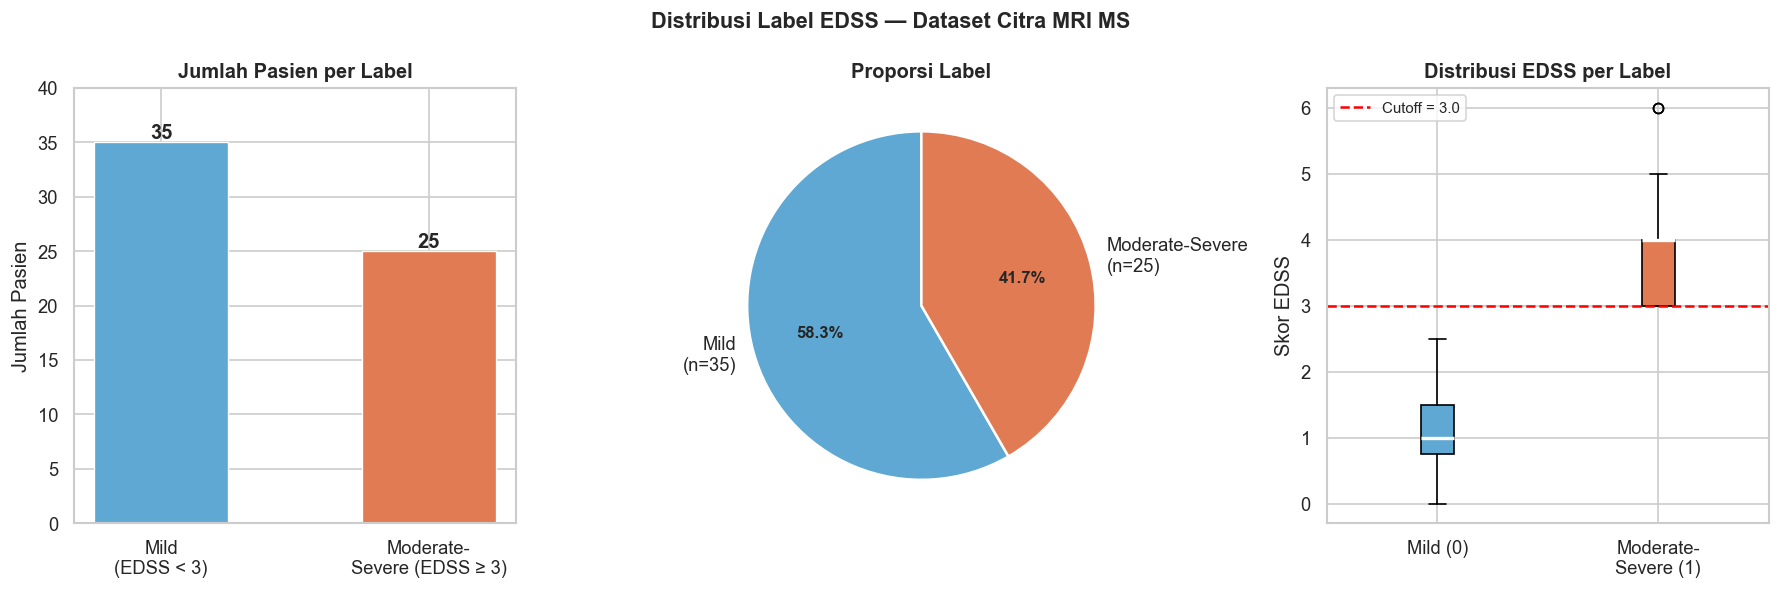

  Visualisasi tersimpan: label_distribution.png


   Section 6 — Finalisasi DataFrame
  Shape df_final         : (60, 45)
  Kolom label tersedia   : ✓
  Distribusi label       : 35 Mild | 25 Moderate-Severe
  Missing values label   : 0
  Backup CSV tersimpan   : df_final_labeled.csv

  df_final dengan kolom label siap untuk Cell 9.

  Cell 8 selesai. Lanjut ke Cell 9 — Class Imbalance.


In [8]:
# CELL 8 — BUAT LABEL DARI EDSS
# Deskripsi: Konversi nilai EDSS kontinu menjadi label biner
#            berdasarkan cutoff yang disepakati:
#            EDSS < 3  → Label 0 (Mild)
#            EDSS ≥ 3  → Label 1 (Moderate-Severe)
# ============================================================

# ── Section 1 — Definisi Cutoff & Pembuatan Label ───────────
print("=" * 55)
print("   Section 1 — Definisi Cutoff & Pembuatan Label")
print("=" * 55)

EDSS_CUTOFF = 3.0

print(f"  Cutoff EDSS yang digunakan : {EDSS_CUTOFF}")
print(f"  Label 0 = Mild             : EDSS < {EDSS_CUTOFF}")
print(f"  Label 1 = Moderate-Severe  : EDSS ≥ {EDSS_CUTOFF}")

# Buat kolom label
df_final['label'] = (df_final['EDSS'] >= EDSS_CUTOFF).astype(int)

print(f"\n  Kolom 'label' berhasil dibuat ✓")
print(f"  Posisi kolom  : {list(df_final.columns).index('label') + 1}"
      f" dari {df_final.shape[1]} kolom")

# ── Section 2 — Verifikasi Mapping EDSS ke Label ────────────
print("\n")
print("=" * 55)
print("   Section 2 — Verifikasi Mapping EDSS ke Label")
print("=" * 55)

# Tampilkan semua nilai EDSS unik dan label hasil mapping
edss_label_map = (df_final[['EDSS', 'label']]
                  .drop_duplicates()
                  .sort_values('EDSS')
                  .reset_index(drop=True))

print("  Mapping nilai EDSS → Label:")
print(f"  {'EDSS':<10} {'Label':<8} {'Kategori'}")
print("  " + "-" * 35)
for _, row in edss_label_map.iterrows():
    kategori = "Mild" if row['label'] == 0 else "Moderate-Severe"
    marker   = "← batas cutoff" if row['EDSS'] == EDSS_CUTOFF else ""
    print(f"  {row['EDSS']:<10.1f} {int(row['label']):<8} "
          f"{kategori}  {marker}")

# ── Section 3 — Distribusi Label ────────────────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Distribusi Label")
print("=" * 55)

label_counts = df_final['label'].value_counts().sort_index()
n_total      = len(df_final)

for label_val, count in label_counts.items():
    kategori = "Mild" if label_val == 0 else "Moderate-Severe"
    pct      = count / n_total * 100
    bar      = '█' * int(pct / 2)
    print(f"  Label {label_val} ({kategori:<16}): "
          f"{count:>2} pasien ({pct:.1f}%) {bar}")

rasio = label_counts[0] / label_counts[1]
print(f"\n  Rasio Label 0 : Label 1 = "
      f"{label_counts[0]} : {label_counts[1]} "
      f"({rasio:.2f} : 1)")

# Evaluasi keseimbangan
if rasio <= 1.5:
    status_balance = "✓ SEIMBANG — SMOTE opsional di Cell 9"
elif rasio <= 2.5:
    status_balance = "⚠ CUKUP SEIMBANG — evaluasi SMOTE di Cell 9"
else:
    status_balance = "✗ TIDAK SEIMBANG — SMOTE wajib di Cell 9"

print(f"  Status imbalance          : {status_balance}")

# ── Section 4 — Distribusi EDSS per Label ───────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Distribusi EDSS per Label")
print("=" * 55)

print("  Statistik EDSS per label:")
edss_stats = df_final.groupby('label')['EDSS'].agg(
    ['count', 'min', 'max', 'mean', 'median']
)
edss_stats.index = ['Mild (0)', 'Moderate-Severe (1)']
print(edss_stats.to_string())

print("\n  Distribusi nilai EDSS per label:")
for label_val in [0, 1]:
    kategori  = "Mild" if label_val == 0 else "Moderate-Severe"
    edss_vals = (df_final[df_final['label'] == label_val]['EDSS']
                 .value_counts()
                 .sort_index())
    print(f"\n  Label {label_val} — {kategori}:")
    for edss_val, cnt in edss_vals.items():
        print(f"    EDSS {edss_val:.1f} : {cnt} pasien")

# ── Section 5 — Visualisasi Distribusi Label ────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Visualisasi Distribusi Label")
print("=" * 55)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Distribusi Label EDSS — Dataset Citra MRI MS',
             fontsize=13, fontweight='bold')

colors = {0: '#5fa8d3', 1: '#e07b54'}

# Plot 1 — Bar chart distribusi label
ax1 = axes[0]
bars = ax1.bar(
    ['Mild\n(EDSS < 3)', 'Moderate-\nSevere (EDSS ≥ 3)'],
    [label_counts[0], label_counts[1]],
    color=[colors[0], colors[1]],
    edgecolor='white', linewidth=0.8, width=0.5
)
for bar, val in zip(bars, [label_counts[0], label_counts[1]]):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3,
             str(val), ha='center', fontweight='bold')
ax1.set_title('Jumlah Pasien per Label', fontweight='bold')
ax1.set_ylabel('Jumlah Pasien')
ax1.set_ylim(0, max(label_counts) + 5)

# Plot 2 — Pie chart proporsi
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    [label_counts[0], label_counts[1]],
    labels=[f'Mild\n(n={label_counts[0]})',
            f'Moderate-Severe\n(n={label_counts[1]})'],
    autopct='%1.1f%%',
    colors=[colors[0], colors[1]],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
ax2.set_title('Proporsi Label', fontweight='bold')

# Plot 3 — Boxplot EDSS per label
ax3 = axes[2]
data_box = [
    df_final[df_final['label'] == 0]['EDSS'].values,
    df_final[df_final['label'] == 1]['EDSS'].values
]
bp = ax3.boxplot(data_box, patch_artist=True,
                 medianprops={'color': 'white',
                              'linewidth': 2})
for patch, color in zip(bp['boxes'], [colors[0], colors[1]]):
    patch.set_facecolor(color)
ax3.axhline(y=EDSS_CUTOFF, color='red', linestyle='--',
            linewidth=1.5, label=f'Cutoff = {EDSS_CUTOFF}')
ax3.set_xticklabels(['Mild (0)', 'Moderate-\nSevere (1)'])
ax3.set_title('Distribusi EDSS per Label', fontweight='bold')
ax3.set_ylabel('Skor EDSS')
ax3.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, 'label_distribution.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Visualisasi tersimpan: label_distribution.png")

# ── Section 6 — Finalisasi & Simpan ─────────────────────────
print("\n")
print("=" * 55)
print("   Section 6 — Finalisasi DataFrame")
print("=" * 55)

# Simpan df_final yang sudah ada kolom label
output_path_labeled = os.path.join(BASE_PATH, 'df_final_labeled.csv')
df_final.to_csv(output_path_labeled, index=False)

print(f"  Shape df_final         : {df_final.shape}")
print(f"  Kolom label tersedia   : "
      f"{'✓' if 'label' in df_final.columns else '✗'}")
print(f"  Distribusi label       : "
      f"{label_counts[0]} Mild | {label_counts[1]} Moderate-Severe")
print(f"  Missing values label   : "
      f"{df_final['label'].isnull().sum()}")
print(f"  Backup CSV tersimpan   : df_final_labeled.csv")
print(f"\n  df_final dengan kolom label siap untuk Cell 9.")
print("\n  Cell 8 selesai. Lanjut ke Cell 9 — Class Imbalance.")

In [9]:
# ============================================================
# CELL 9 — PENGECEKAN CLASS IMBALANCE
# Deskripsi: Evaluasi formal distribusi label, keputusan
#            penerapan SMOTE, dan persiapan X dan y final
#            untuk pipeline modeling
# ============================================================

# ── Section 1 — Persiapan Fitur dan Label ───────────────────
print("=" * 55)
print("   Section 1 — Persiapan Fitur dan Label")
print("=" * 55)

# Fitur yang digunakan: 15 fitur radiomik saja
# Kolom klinis (EDSS, Gender, dll) TIDAK dimasukkan sebagai
# fitur karena EDSS adalah sumber label, dan kolom klinis
# lainnya bukan hasil ekstraksi citra
FEATURE_COLS = [c for c in df_final.columns
                if any(s in c for s in
                       ['flair_', 't1_', 't2_'])]
TARGET_COL   = 'label'

X = df_final[FEATURE_COLS].values
y = df_final[TARGET_COL].values

print(f"  Fitur yang digunakan  : {len(FEATURE_COLS)} fitur radiomik")
for i, col in enumerate(FEATURE_COLS, 1):
    print(f"    {i:02d}. {col}")
print(f"\n  Shape X               : {X.shape}")
print(f"  Shape y               : {y.shape}")
print(f"  Target kolom          : {TARGET_COL}")

# ── Section 2 — Evaluasi Imbalance Ratio ────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Evaluasi Class Imbalance")
print("=" * 55)

n_total    = len(y)
n_mild     = (y == 0).sum()
n_severe   = (y == 1).sum()
ir         = n_mild / n_severe   # Imbalance Ratio

print(f"  Label 0 — Mild             : {n_mild} pasien "
      f"({n_mild/n_total*100:.1f}%)")
print(f"  Label 1 — Moderate-Severe  : {n_severe} pasien "
      f"({n_severe/n_total*100:.1f}%)")
print(f"\n  Imbalance Ratio (IR)       : {ir:.4f}")
print(f"  Threshold SMOTE            : IR > 1.5")

if ir <= 1.5:
    smote_decision = False
    print(f"\n  Keputusan : ✓ SMOTE TIDAK DITERAPKAN")
    print(f"  Alasan    : IR = {ir:.2f} ≤ 1.5 — distribusi label")
    print(f"              sudah cukup seimbang untuk training")
    print(f"              model tanpa augmentasi sintetis.")
elif ir <= 2.5:
    smote_decision = True
    print(f"\n  Keputusan : ⚠ SMOTE DITERAPKAN (IR moderat)")
else:
    smote_decision = True
    print(f"\n  Keputusan : ✗ SMOTE DITERAPKAN (IR tinggi)")

# ── Section 3 — Eksekusi Keputusan SMOTE ────────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Eksekusi Keputusan SMOTE")
print("=" * 55)

if smote_decision:
    print("  Menerapkan SMOTE...")
    smote   = SMOTE(random_state=42)
    X_final, y_final = smote.fit_resample(X, y)
    print(f"  Shape X sebelum SMOTE : {X.shape}")
    print(f"  Shape X setelah SMOTE : {X_final.shape}")
    n_mild_new   = (y_final == 0).sum()
    n_severe_new = (y_final == 1).sum()
    print(f"  Distribusi baru       : "
          f"{n_mild_new} Mild | {n_severe_new} Moderate-Severe")
    print(f"  IR setelah SMOTE      : "
          f"{n_mild_new/n_severe_new:.4f}")
else:
    X_final, y_final = X, y
    print("  SMOTE tidak diterapkan.")
    print(f"  X_final shape : {X_final.shape}")
    print(f"  y_final shape : {y_final.shape}")
    print(f"  Distribusi    : {n_mild} Mild | "
          f"{n_severe} Moderate-Severe")
    print(f"\n  Justifikasi akademik:")
    print(f"  Berdasarkan panduan Chawla et al. (2002) dan")
    print(f"  He & Garcia (2009), teknik oversampling seperti")
    print(f"  SMOTE direkomendasikan ketika imbalance ratio")
    print(f"  melebihi 1.5:1. Dengan IR = {ir:.2f}:1 pada")
    print(f"  dataset ini, distribusi label dinilai cukup")
    print(f"  seimbang sehingga SMOTE tidak diperlukan dan")
    print(f"  berpotensi menambahkan noise sintetis yang")
    print(f"  tidak perlu pada dataset berukuran kecil (n=60).")

# ── Section 4 — Ringkasan Final ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Ringkasan Hasil Cell 9")
print("=" * 55)

print(f"  SMOTE diterapkan      : {'Ya' if smote_decision else 'Tidak'}")
print(f"  Shape X_final         : {X_final.shape}")
print(f"  Shape y_final         : {y_final.shape}")
print(f"  Jumlah fitur          : {X_final.shape[1]}")
print(f"  Jumlah sampel         : {X_final.shape[0]}")
print(f"  Distribusi label      : "
      f"{(y_final==0).sum()} Mild | "
      f"{(y_final==1).sum()} Moderate-Severe")
print(f"\n  X_final dan y_final siap untuk Cell 10.")
print("\n  Cell 9 selesai. Lanjut ke Cell 10 — Split & Normalisasi.")

   Section 1 — Persiapan Fitur dan Label
  Fitur yang digunakan  : 15 fitur radiomik
    01. flair_lesion_volume
    02. flair_mean_intensity
    03. flair_std_intensity
    04. flair_lesion_count
    05. flair_lesion_ratio
    06. t1_lesion_volume
    07. t1_mean_intensity
    08. t1_std_intensity
    09. t1_lesion_count
    10. t1_lesion_ratio
    11. t2_lesion_volume
    12. t2_mean_intensity
    13. t2_std_intensity
    14. t2_lesion_count
    15. t2_lesion_ratio

  Shape X               : (60, 15)
  Shape y               : (60,)
  Target kolom          : label


   Section 2 — Evaluasi Class Imbalance
  Label 0 — Mild             : 35 pasien (58.3%)
  Label 1 — Moderate-Severe  : 25 pasien (41.7%)

  Imbalance Ratio (IR)       : 1.4000
  Threshold SMOTE            : IR > 1.5

  Keputusan : ✓ SMOTE TIDAK DITERAPKAN
  Alasan    : IR = 1.40 ≤ 1.5 — distribusi label
              sudah cukup seimbang untuk training
              model tanpa augmentasi sintetis.


   Section 3 — Ekseku

In [10]:
# CELL 10 — SPLIT DATA & NORMALISASI
# Deskripsi: Train/test split dengan stratifikasi dan
#            StandardScaler normalisasi fitur radiomik.
#            Identik dengan Cell 7 & 8 pipeline tabular.
# ============================================================

# ── Section 1 — Train/Test Split ────────────────────────────
print("=" * 55)
print("   Section 1 — Train/Test Split")
print("=" * 55)

TEST_SIZE    = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final,
    test_size    = TEST_SIZE,
    random_state = RANDOM_STATE,
    stratify     = y_final   # jaga proporsi label di tiap subset
)

print(f"  Strategi split        : Stratified Train/Test Split")
print(f"  Rasio split           : {int((1-TEST_SIZE)*100)}% "
      f"train — {int(TEST_SIZE*100)}% test")
print(f"  Random state          : {RANDOM_STATE}")
print(f"\n  Shape X_train         : {X_train.shape}")
print(f"  Shape X_test          : {X_test.shape}")
print(f"  Shape y_train         : {y_train.shape}")
print(f"  Shape y_test          : {y_test.shape}")

# Verifikasi proporsi label di tiap subset
print(f"\n  Distribusi label setelah split:")
print(f"  {'Subset':<12} {'Mild (0)':<12} "
      f"{'Mod-Severe (1)':<16} {'Total'}")
print("  " + "-" * 48)

for subset_name, y_sub in [("Train", y_train), ("Test", y_test)]:
    n0  = (y_sub == 0).sum()
    n1  = (y_sub == 1).sum()
    tot = len(y_sub)
    print(f"  {subset_name:<12} {n0:<5} ({n0/tot*100:.1f}%)  "
          f"  {n1:<5} ({n1/tot*100:.1f}%)      {tot}")

# ── Section 2 — Normalisasi Fitur (StandardScaler) ──────────
print("\n")
print("=" * 55)
print("   Section 2 — Normalisasi Fitur (StandardScaler)")
print("=" * 55)

print("  Metode    : StandardScaler (Z-score normalization)")
print("  Formula   : z = (x - mean) / std")
print("  Fit pada  : X_train saja (mencegah data leakage)")
print("  Transform : X_train dan X_test")

scaler   = StandardScaler()

# Fit HANYA pada training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data menggunakan parameter dari training
X_test_scaled  = scaler.transform(X_test)

print(f"\n  Parameter scaler (dari X_train):")
print(f"  Mean fitur  : min={scaler.mean_.min():.4f}, "
      f"max={scaler.mean_.max():.4f}")
print(f"  Std fitur   : min={scaler.scale_.min():.4f}, "
      f"max={scaler.scale_.max():.4f}")

# Verifikasi hasil scaling pada X_train
print(f"\n  Verifikasi X_train_scaled:")
print(f"  Mean (expected ≈ 0) : {X_train_scaled.mean():.6f}")
print(f"  Std  (expected ≈ 1) : {X_train_scaled.std():.6f}")

print(f"\n  Verifikasi X_test_scaled:")
print(f"  Mean                : {X_test_scaled.mean():.6f}")
print(f"  Std                 : {X_test_scaled.std():.6f}")
print("  (Test mean/std tidak harus = 0/1 karena")
print("   scaler di-fit pada train, bukan test)")

# ── Section 3 — Preview Fitur Sebelum & Sesudah Scaling ─────
print("\n")
print("=" * 55)
print("   Section 3 — Perbandingan Sebelum & Sesudah Scaling")
print("=" * 55)

df_before = pd.DataFrame(X_train, columns=FEATURE_COLS)
df_after  = pd.DataFrame(X_train_scaled, columns=FEATURE_COLS)

print("  Statistik X_train SEBELUM scaling:")
print(f"  {'Fitur':<28} {'Min':>10} {'Max':>12} {'Mean':>12}")
print("  " + "-" * 65)
for col in FEATURE_COLS:
    print(f"  {col:<28} "
          f"{df_before[col].min():>10.2f} "
          f"{df_before[col].max():>12.2f} "
          f"{df_before[col].mean():>12.4f}")

print(f"\n  Statistik X_train SESUDAH scaling:")
print(f"  {'Fitur':<28} {'Min':>10} {'Max':>12} {'Mean':>12}")
print("  " + "-" * 65)
for col in FEATURE_COLS:
    print(f"  {col:<28} "
          f"{df_after[col].min():>10.4f} "
          f"{df_after[col].max():>12.4f} "
          f"{df_after[col].mean():>12.6f}")

# ── Section 4 — Ringkasan & Simpan Objek Penting ────────────
print("\n")
print("=" * 55)
print("   Section 4 — Ringkasan & Simpan Objek")
print("=" * 55)

print(f"  X_train_scaled : {X_train_scaled.shape} — input training model")
print(f"  X_test_scaled  : {X_test_scaled.shape}  — input evaluasi model")
print(f"  y_train        : {y_train.shape} — label training")
print(f"  y_test         : {y_test.shape}  — label evaluasi")
print(f"  scaler         : StandardScaler (tersimpan di memory)")

# K-Fold configuration — ditetapkan di sini agar konsisten
# dengan pipeline tabular (jumlah fold identik)
N_SPLITS     = 5
KFOLD_RANDOM = 42

skf = StratifiedKFold(
    n_splits     = N_SPLITS,
    shuffle      = True,
    random_state = KFOLD_RANDOM
)

print(f"\n  Konfigurasi K-Fold Cross Validation:")
print(f"  Jenis          : Stratified K-Fold")
print(f"  Jumlah fold    : {N_SPLITS} fold")
print(f"  Random state   : {KFOLD_RANDOM}")
print(f"  (Identik dengan konfigurasi di pipeline tabular)")

print(f"\n  Semua objek siap untuk Cell 11 — Training Model.")
print("\n  Cell 10 selesai. Lanjut ke Cell 11 — Gradient Boosting.")

   Section 1 — Train/Test Split
  Strategi split        : Stratified Train/Test Split
  Rasio split           : 80% train — 20% test
  Random state          : 42

  Shape X_train         : (48, 15)
  Shape X_test          : (12, 15)
  Shape y_train         : (48,)
  Shape y_test          : (12,)

  Distribusi label setelah split:
  Subset       Mild (0)     Mod-Severe (1)   Total
  ------------------------------------------------
  Train        28    (58.3%)    20    (41.7%)      48
  Test         7     (58.3%)    5     (41.7%)      12


   Section 2 — Normalisasi Fitur (StandardScaler)
  Metode    : StandardScaler (Z-score normalization)
  Formula   : z = (x - mean) / std
  Fit pada  : X_train saja (mencegah data leakage)
  Transform : X_train dan X_test

  Parameter scaler (dari X_train):
  Mean fitur  : min=0.0004, max=6612.3333
  Std fitur   : min=0.0005, max=10983.9128

  Verifikasi X_train_scaled:
  Mean (expected ≈ 0) : 0.000000
  Std  (expected ≈ 1) : 1.000000

  Verifikasi X_t

In [11]:
# ============================================================
# CELL 11 — GRADIENT BOOSTING + K-FOLD CROSS VALIDATION
# Deskripsi: Training dan evaluasi Gradient Boosting dengan
#            Stratified K-Fold 5-fold pada dataset citra MRI.
#            Hyperparameter identik dengan pipeline tabular.
# ============================================================

# ── Section 1 — Konfigurasi Model ───────────────────────────
print("=" * 55)
print("   Section 1 — Konfigurasi Gradient Boosting")
print("=" * 55)

gb_model = GradientBoostingClassifier(
    n_estimators   = 100,
    learning_rate  = 0.1,
    max_depth      = 3,
    random_state   = RANDOM_STATE
)

print("  Model         : Gradient Boosting Classifier")
print("  n_estimators  : 100")
print("  learning_rate : 0.1")
print("  max_depth     : 3")
print(f"  random_state  : {RANDOM_STATE}")
print("  (Identik dengan konfigurasi di pipeline tabular)")

# ── Section 2 — K-Fold Cross Validation ─────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Stratified K-Fold Cross Validation")
print("=" * 55)

# Metrik yang dievaluasi per fold
scoring = {
    'accuracy'  : 'accuracy',
    'precision' : 'precision_weighted',
    'recall'    : 'recall_weighted',
    'f1'        : 'f1_weighted',
    'roc_auc'   : 'roc_auc'
}

print(f"  Menjalankan {N_SPLITS}-Fold CV pada X_train_scaled...")
print(f"  Jumlah sampel training : {X_train_scaled.shape[0]}")
print(f"  Jumlah fitur           : {X_train_scaled.shape[1]}\n")

cv_results_gb = cross_validate(
    gb_model,
    X_train_scaled, y_train,
    cv            = skf,
    scoring       = scoring,
    return_train_score = False
)

# Tampilkan hasil per fold
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>11} "
      f"{'Recall':>8} {'F1':>8} {'AUC-ROC':>9}")
print("  " + "-" * 55)

for fold in range(N_SPLITS):
    print(f"  {fold+1:<6} "
          f"{cv_results_gb['test_accuracy'][fold]:>10.4f} "
          f"{cv_results_gb['test_precision'][fold]:>11.4f} "
          f"{cv_results_gb['test_recall'][fold]:>8.4f} "
          f"{cv_results_gb['test_f1'][fold]:>8.4f} "
          f"{cv_results_gb['test_roc_auc'][fold]:>9.4f}")

print("  " + "-" * 55)

# Rata-rata dan std tiap metrik
gb_cv_mean = {
    'accuracy'  : cv_results_gb['test_accuracy'].mean(),
    'precision' : cv_results_gb['test_precision'].mean(),
    'recall'    : cv_results_gb['test_recall'].mean(),
    'f1'        : cv_results_gb['test_f1'].mean(),
    'roc_auc'   : cv_results_gb['test_roc_auc'].mean()
}
gb_cv_std = {
    'accuracy'  : cv_results_gb['test_accuracy'].std(),
    'precision' : cv_results_gb['test_precision'].std(),
    'recall'    : cv_results_gb['test_recall'].std(),
    'f1'        : cv_results_gb['test_f1'].std(),
    'roc_auc'   : cv_results_gb['test_roc_auc'].std()
}

print(f"  {'Mean':<6} "
      f"{gb_cv_mean['accuracy']:>10.4f} "
      f"{gb_cv_mean['precision']:>11.4f} "
      f"{gb_cv_mean['recall']:>8.4f} "
      f"{gb_cv_mean['f1']:>8.4f} "
      f"{gb_cv_mean['roc_auc']:>9.4f}")
print(f"  {'Std':<6} "
      f"{gb_cv_std['accuracy']:>10.4f} "
      f"{gb_cv_std['precision']:>11.4f} "
      f"{gb_cv_std['recall']:>8.4f} "
      f"{gb_cv_std['f1']:>8.4f} "
      f"{gb_cv_std['roc_auc']:>9.4f}")

# ── Section 3 — Training Final & Evaluasi Test Set ──────────
print("\n")
print("=" * 55)
print("   Section 3 — Training Final & Evaluasi Test Set")
print("=" * 55)

# Fit model pada seluruh data training
gb_model.fit(X_train_scaled, y_train)
y_pred_gb  = gb_model.predict(X_test_scaled)
y_prob_gb  = gb_model.predict_proba(X_test_scaled)[:, 1]

# Hitung metrik pada test set
gb_test_metrics = {
    'accuracy'  : accuracy_score(y_test, y_pred_gb),
    'precision' : precision_score(y_test, y_pred_gb,
                                  average='weighted',
                                  zero_division=0),
    'recall'    : recall_score(y_test, y_pred_gb,
                               average='weighted',
                               zero_division=0),
    'f1'        : f1_score(y_test, y_pred_gb,
                           average='weighted',
                           zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_prob_gb)
}

print("  Metrik evaluasi pada Test Set (12 sampel):")
print(f"  {'Metrik':<12} {'Nilai':>10}")
print("  " + "-" * 25)
for metric, val in gb_test_metrics.items():
    print(f"  {metric:<12} {val:>10.4f}")

# Confusion Matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)
print(f"\n  Confusion Matrix (Test Set):")
print(f"  {'':>20} Pred Mild  Pred Severe")
print(f"  Actual Mild    :  {cm_gb[0,0]:>6}      {cm_gb[0,1]:>6}")
print(f"  Actual Severe  :  {cm_gb[1,0]:>6}      {cm_gb[1,1]:>6}")

# Classification Report
print(f"\n  Classification Report:")
print(classification_report(
    y_test, y_pred_gb,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

# ── Section 4 — Feature Importance ──────────────────────────
print("=" * 55)
print("   Section 4 — Feature Importance")
print("=" * 55)

fi_gb = pd.Series(
    gb_model.feature_importances_,
    index=FEATURE_COLS
).sort_values(ascending=False)

print("  Top 10 fitur terpenting (Gradient Boosting):")
print(f"  {'Fitur':<28} {'Importance':>12}")
print("  " + "-" * 42)
for feat, imp in fi_gb.head(10).items():
    bar = '█' * int(imp * 100)
    print(f"  {feat:<28} {imp:>10.4f}  {bar}")

# ── Section 5 — Ringkasan Hasil GB ──────────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Ringkasan Hasil Gradient Boosting")
print("=" * 55)

print(f"  CV Mean Accuracy   : {gb_cv_mean['accuracy']:.4f} "
      f"(±{gb_cv_std['accuracy']:.4f})")
print(f"  CV Mean F1         : {gb_cv_mean['f1']:.4f} "
      f"(±{gb_cv_std['f1']:.4f})")
print(f"  CV Mean AUC-ROC    : {gb_cv_mean['roc_auc']:.4f} "
      f"(±{gb_cv_std['roc_auc']:.4f})")
print(f"\n  Test Accuracy      : {gb_test_metrics['accuracy']:.4f}")
print(f"  Test F1            : {gb_test_metrics['f1']:.4f}")
print(f"  Test AUC-ROC       : {gb_test_metrics['roc_auc']:.4f}")

# Simpan hasil untuk Cell 14 (evaluasi komparatif)
gb_results = {
    'model'          : 'Gradient Boosting',
    'cv_mean'        : gb_cv_mean,
    'cv_std'         : gb_cv_std,
    'test_metrics'   : gb_test_metrics,
    'y_pred'         : y_pred_gb,
    'y_prob'         : y_prob_gb,
    'confusion_matrix': cm_gb,
    'feature_importance': fi_gb
}

print(f"\n  gb_results tersimpan di memory untuk Cell 14.")
print("\n  Cell 11 selesai. Lanjut ke Cell 12 — XGBoost + K-Fold.")

   Section 1 — Konfigurasi Gradient Boosting
  Model         : Gradient Boosting Classifier
  n_estimators  : 100
  learning_rate : 0.1
  max_depth     : 3
  random_state  : 42
  (Identik dengan konfigurasi di pipeline tabular)


   Section 2 — Stratified K-Fold Cross Validation
  Menjalankan 5-Fold CV pada X_train_scaled...
  Jumlah sampel training : 48
  Jumlah fitur           : 15

  Fold     Accuracy   Precision   Recall       F1   AUC-ROC
  -------------------------------------------------------
  1          0.6000      0.8000   0.6000   0.5667    0.5417
  2          0.5000      0.3333   0.5000   0.4000    0.4583
  3          0.5000      0.5714   0.5000   0.4848    0.5417
  4          0.4444      0.2778   0.4444   0.3419    0.6000
  5          0.4444      0.2778   0.4444   0.3419    0.4500
  -------------------------------------------------------
  Mean       0.4978      0.4521   0.4978   0.4271    0.5183
  Std        0.0568      0.2050   0.0568   0.0873    0.0566


   Section 3 —

In [12]:
# ============================================================
# CELL 12 — XGBOOST + K-FOLD CROSS VALIDATION
# Deskripsi: Training dan evaluasi XGBoost dengan Stratified
#            K-Fold 5-fold pada dataset citra MRI.
#            Hyperparameter identik dengan pipeline tabular.
# ============================================================

# ── Section 1 — Konfigurasi Model ───────────────────────────
print("=" * 55)
print("   Section 1 — Konfigurasi XGBoost")
print("=" * 55)

xgb_model = XGBClassifier(
    n_estimators   = 100,
    learning_rate  = 0.1,
    max_depth      = 3,
    random_state   = RANDOM_STATE,
    eval_metric    = 'logloss',
    verbosity      = 0
)

print("  Model         : XGBoost Classifier")
print("  n_estimators  : 100")
print("  learning_rate : 0.1")
print("  max_depth     : 3")
print(f"  random_state  : {RANDOM_STATE}")
print("  eval_metric   : logloss")
print("  (Identik dengan konfigurasi di pipeline tabular)")

# ── Section 2 — K-Fold Cross Validation ─────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Stratified K-Fold Cross Validation")
print("=" * 55)

scoring = {
    'accuracy'  : 'accuracy',
    'precision' : 'precision_weighted',
    'recall'    : 'recall_weighted',
    'f1'        : 'f1_weighted',
    'roc_auc'   : 'roc_auc'
}

print(f"  Menjalankan {N_SPLITS}-Fold CV pada X_train_scaled...")
print(f"  Jumlah sampel training : {X_train_scaled.shape[0]}")
print(f"  Jumlah fitur           : {X_train_scaled.shape[1]}\n")

cv_results_xgb = cross_validate(
    xgb_model,
    X_train_scaled, y_train,
    cv                 = skf,
    scoring            = scoring,
    return_train_score = False
)

# Tampilkan hasil per fold
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>11} "
      f"{'Recall':>8} {'F1':>8} {'AUC-ROC':>9}")
print("  " + "-" * 55)

for fold in range(N_SPLITS):
    print(f"  {fold+1:<6} "
          f"{cv_results_xgb['test_accuracy'][fold]:>10.4f} "
          f"{cv_results_xgb['test_precision'][fold]:>11.4f} "
          f"{cv_results_xgb['test_recall'][fold]:>8.4f} "
          f"{cv_results_xgb['test_f1'][fold]:>8.4f} "
          f"{cv_results_xgb['test_roc_auc'][fold]:>9.4f}")

print("  " + "-" * 55)

xgb_cv_mean = {
    'accuracy'  : cv_results_xgb['test_accuracy'].mean(),
    'precision' : cv_results_xgb['test_precision'].mean(),
    'recall'    : cv_results_xgb['test_recall'].mean(),
    'f1'        : cv_results_xgb['test_f1'].mean(),
    'roc_auc'   : cv_results_xgb['test_roc_auc'].mean()
}
xgb_cv_std = {
    'accuracy'  : cv_results_xgb['test_accuracy'].std(),
    'precision' : cv_results_xgb['test_precision'].std(),
    'recall'    : cv_results_xgb['test_recall'].std(),
    'f1'        : cv_results_xgb['test_f1'].std(),
    'roc_auc'   : cv_results_xgb['test_roc_auc'].std()
}

print(f"  {'Mean':<6} "
      f"{xgb_cv_mean['accuracy']:>10.4f} "
      f"{xgb_cv_mean['precision']:>11.4f} "
      f"{xgb_cv_mean['recall']:>8.4f} "
      f"{xgb_cv_mean['f1']:>8.4f} "
      f"{xgb_cv_mean['roc_auc']:>9.4f}")
print(f"  {'Std':<6} "
      f"{xgb_cv_std['accuracy']:>10.4f} "
      f"{xgb_cv_std['precision']:>11.4f} "
      f"{xgb_cv_std['recall']:>8.4f} "
      f"{xgb_cv_std['f1']:>8.4f} "
      f"{xgb_cv_std['roc_auc']:>9.4f}")

# ── Section 3 — Training Final & Evaluasi Test Set ──────────
print("\n")
print("=" * 55)
print("   Section 3 — Training Final & Evaluasi Test Set")
print("=" * 55)

xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

xgb_test_metrics = {
    'accuracy'  : accuracy_score(y_test, y_pred_xgb),
    'precision' : precision_score(y_test, y_pred_xgb,
                                  average='weighted',
                                  zero_division=0),
    'recall'    : recall_score(y_test, y_pred_xgb,
                               average='weighted',
                               zero_division=0),
    'f1'        : f1_score(y_test, y_pred_xgb,
                           average='weighted',
                           zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_prob_xgb)
}

print("  Metrik evaluasi pada Test Set (12 sampel):")
print(f"  {'Metrik':<12} {'Nilai':>10}")
print("  " + "-" * 25)
for metric, val in xgb_test_metrics.items():
    print(f"  {metric:<12} {val:>10.4f}")

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
print(f"\n  Confusion Matrix (Test Set):")
print(f"  {'':>20} Pred Mild  Pred Severe")
print(f"  Actual Mild    :  {cm_xgb[0,0]:>6}      {cm_xgb[0,1]:>6}")
print(f"  Actual Severe  :  {cm_xgb[1,0]:>6}      {cm_xgb[1,1]:>6}")

print(f"\n  Classification Report:")
print(classification_report(
    y_test, y_pred_xgb,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

# ── Section 4 — Feature Importance ──────────────────────────
print("=" * 55)
print("   Section 4 — Feature Importance")
print("=" * 55)

fi_xgb = pd.Series(
    xgb_model.feature_importances_,
    index=FEATURE_COLS
).sort_values(ascending=False)

print("  Top 10 fitur terpenting (XGBoost):")
print(f"  {'Fitur':<28} {'Importance':>12}")
print("  " + "-" * 42)
for feat, imp in fi_xgb.head(10).items():
    bar = '█' * int(imp * 100)
    print(f"  {feat:<28} {imp:>10.4f}  {bar}")

# ── Section 5 — Ringkasan Hasil XGBoost ─────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Ringkasan Hasil XGBoost")
print("=" * 55)

print(f"  CV Mean Accuracy   : {xgb_cv_mean['accuracy']:.4f} "
      f"(±{xgb_cv_std['accuracy']:.4f})")
print(f"  CV Mean F1         : {xgb_cv_mean['f1']:.4f} "
      f"(±{xgb_cv_std['f1']:.4f})")
print(f"  CV Mean AUC-ROC    : {xgb_cv_mean['roc_auc']:.4f} "
      f"(±{xgb_cv_std['roc_auc']:.4f})")
print(f"\n  Test Accuracy      : {xgb_test_metrics['accuracy']:.4f}")
print(f"  Test F1            : {xgb_test_metrics['f1']:.4f}")
print(f"  Test AUC-ROC       : {xgb_test_metrics['roc_auc']:.4f}")

# Simpan hasil untuk Cell 14
xgb_results = {
    'model'             : 'XGBoost',
    'cv_mean'           : xgb_cv_mean,
    'cv_std'            : xgb_cv_std,
    'test_metrics'      : xgb_test_metrics,
    'y_pred'            : y_pred_xgb,
    'y_prob'            : y_prob_xgb,
    'confusion_matrix'  : cm_xgb,
    'feature_importance': fi_xgb
}

print(f"\n  xgb_results tersimpan di memory untuk Cell 14.")
print("\n  Cell 12 selesai. Lanjut ke Cell 13 — MLP + K-Fold.")

   Section 1 — Konfigurasi XGBoost
  Model         : XGBoost Classifier
  n_estimators  : 100
  learning_rate : 0.1
  max_depth     : 3
  random_state  : 42
  eval_metric   : logloss
  (Identik dengan konfigurasi di pipeline tabular)


   Section 2 — Stratified K-Fold Cross Validation
  Menjalankan 5-Fold CV pada X_train_scaled...
  Jumlah sampel training : 48
  Jumlah fitur           : 15

  Fold     Accuracy   Precision   Recall       F1   AUC-ROC
  -------------------------------------------------------
  1          0.7000      0.8286   0.7000   0.6909    0.5833
  2          0.4000      0.3000   0.4000   0.3429    0.4167
  3          0.6000      0.6000   0.6000   0.6000    0.7500
  4          0.6667      0.7917   0.6667   0.6051    0.6500
  5          0.6667      0.7917   0.6667   0.6051    0.4500
  -------------------------------------------------------
  Mean       0.6067      0.6624   0.6067   0.5688    0.5700
  Std        0.1083      0.1981   0.1083   0.1180    0.1240


   Secti

In [13]:
# ============================================================
# CELL 13 — MLP + K-FOLD CROSS VALIDATION
# Deskripsi: Training dan evaluasi MLP dengan Stratified
#            K-Fold 5-fold pada dataset citra MRI.
#            Arsitektur dan hyperparameter identik
#            dengan pipeline tabular.
# ============================================================

# ── Section 1 — Konfigurasi Model ───────────────────────────
print("=" * 55)
print("   Section 1 — Konfigurasi MLP")
print("=" * 55)

mlp_model = MLPClassifier(
    hidden_layer_sizes = (100, 50),
    activation         = 'relu',
    solver             = 'adam',
    max_iter           = 500,
    random_state       = RANDOM_STATE,
    early_stopping     = True,
    validation_fraction= 0.1,
    n_iter_no_change   = 10
)

print("  Model              : MLP Classifier")
print("  hidden_layer_sizes : (100, 50)")
print("  activation         : relu")
print("  solver             : adam")
print("  max_iter           : 500")
print(f"  random_state       : {RANDOM_STATE}")
print("  early_stopping     : True")
print("  validation_fraction: 0.1")
print("  n_iter_no_change   : 10")
print("  (Identik dengan konfigurasi di pipeline tabular)")

# ── Section 2 — K-Fold Cross Validation ─────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Stratified K-Fold Cross Validation")
print("=" * 55)

scoring = {
    'accuracy'  : 'accuracy',
    'precision' : 'precision_weighted',
    'recall'    : 'recall_weighted',
    'f1'        : 'f1_weighted',
    'roc_auc'   : 'roc_auc'
}

print(f"  Menjalankan {N_SPLITS}-Fold CV pada X_train_scaled...")
print(f"  Jumlah sampel training : {X_train_scaled.shape[0]}")
print(f"  Jumlah fitur           : {X_train_scaled.shape[1]}\n")

cv_results_mlp = cross_validate(
    mlp_model,
    X_train_scaled, y_train,
    cv                 = skf,
    scoring            = scoring,
    return_train_score = False
)

# Tampilkan hasil per fold
print(f"  {'Fold':<6} {'Accuracy':>10} {'Precision':>11} "
      f"{'Recall':>8} {'F1':>8} {'AUC-ROC':>9}")
print("  " + "-" * 55)

for fold in range(N_SPLITS):
    print(f"  {fold+1:<6} "
          f"{cv_results_mlp['test_accuracy'][fold]:>10.4f} "
          f"{cv_results_mlp['test_precision'][fold]:>11.4f} "
          f"{cv_results_mlp['test_recall'][fold]:>8.4f} "
          f"{cv_results_mlp['test_f1'][fold]:>8.4f} "
          f"{cv_results_mlp['test_roc_auc'][fold]:>9.4f}")

print("  " + "-" * 55)

mlp_cv_mean = {
    'accuracy'  : cv_results_mlp['test_accuracy'].mean(),
    'precision' : cv_results_mlp['test_precision'].mean(),
    'recall'    : cv_results_mlp['test_recall'].mean(),
    'f1'        : cv_results_mlp['test_f1'].mean(),
    'roc_auc'   : cv_results_mlp['test_roc_auc'].mean()
}
mlp_cv_std = {
    'accuracy'  : cv_results_mlp['test_accuracy'].std(),
    'precision' : cv_results_mlp['test_precision'].std(),
    'recall'    : cv_results_mlp['test_recall'].std(),
    'f1'        : cv_results_mlp['test_f1'].std(),
    'roc_auc'   : cv_results_mlp['test_roc_auc'].std()
}

print(f"  {'Mean':<6} "
      f"{mlp_cv_mean['accuracy']:>10.4f} "
      f"{mlp_cv_mean['precision']:>11.4f} "
      f"{mlp_cv_mean['recall']:>8.4f} "
      f"{mlp_cv_mean['f1']:>8.4f} "
      f"{mlp_cv_mean['roc_auc']:>9.4f}")
print(f"  {'Std':<6} "
      f"{mlp_cv_std['accuracy']:>10.4f} "
      f"{mlp_cv_std['precision']:>11.4f} "
      f"{mlp_cv_std['recall']:>8.4f} "
      f"{mlp_cv_std['f1']:>8.4f} "
      f"{mlp_cv_std['roc_auc']:>9.4f}")

# ── Section 3 — Training Final & Evaluasi Test Set ──────────
print("\n")
print("=" * 55)
print("   Section 3 — Training Final & Evaluasi Test Set")
print("=" * 55)

mlp_model.fit(X_train_scaled, y_train)
y_pred_mlp = mlp_model.predict(X_test_scaled)
y_prob_mlp = mlp_model.predict_proba(X_test_scaled)[:, 1]

mlp_test_metrics = {
    'accuracy'  : accuracy_score(y_test, y_pred_mlp),
    'precision' : precision_score(y_test, y_pred_mlp,
                                  average='weighted',
                                  zero_division=0),
    'recall'    : recall_score(y_test, y_pred_mlp,
                               average='weighted',
                               zero_division=0),
    'f1'        : f1_score(y_test, y_pred_mlp,
                           average='weighted',
                           zero_division=0),
    'roc_auc'   : roc_auc_score(y_test, y_prob_mlp)
}

print("  Metrik evaluasi pada Test Set (12 sampel):")
print(f"  {'Metrik':<12} {'Nilai':>10}")
print("  " + "-" * 25)
for metric, val in mlp_test_metrics.items():
    print(f"  {metric:<12} {val:>10.4f}")

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
print(f"\n  Confusion Matrix (Test Set):")
print(f"  {'':>20} Pred Mild  Pred Severe")
print(f"  Actual Mild    :  {cm_mlp[0,0]:>6}      {cm_mlp[0,1]:>6}")
print(f"  Actual Severe  :  {cm_mlp[1,0]:>6}      {cm_mlp[1,1]:>6}")

print(f"\n  Classification Report:")
print(classification_report(
    y_test, y_pred_mlp,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

# ── Section 4 — Informasi Konvergensi MLP ───────────────────
print("=" * 55)
print("   Section 4 — Informasi Konvergensi MLP")
print("=" * 55)

print(f"  Jumlah iterasi training  : {mlp_model.n_iter_}")
print(f"  Loss akhir training      : {mlp_model.loss_:.6f}")

if mlp_model.n_iter_ < 500:
    print(f"  Status konvergensi       : ✓ Konvergen sebelum "
          f"max_iter (early stopping aktif)")
else:
    print(f"  Status konvergensi       : ⚠ Mencapai max_iter "
          f"— belum konvergen penuh")

print(f"\n  Arsitektur MLP:")
print(f"  Input layer   : {X_train_scaled.shape[1]} neuron "
      f"(jumlah fitur)")
print(f"  Hidden layer 1: 100 neuron (ReLU)")
print(f"  Hidden layer 2: 50 neuron (ReLU)")
print(f"  Output layer  : 1 neuron (Sigmoid — binary)")

# ── Section 5 — Ringkasan Hasil MLP ─────────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Ringkasan Hasil MLP")
print("=" * 55)

print(f"  CV Mean Accuracy   : {mlp_cv_mean['accuracy']:.4f} "
      f"(±{mlp_cv_std['accuracy']:.4f})")
print(f"  CV Mean F1         : {mlp_cv_mean['f1']:.4f} "
      f"(±{mlp_cv_std['f1']:.4f})")
print(f"  CV Mean AUC-ROC    : {mlp_cv_mean['roc_auc']:.4f} "
      f"(±{mlp_cv_std['roc_auc']:.4f})")
print(f"\n  Test Accuracy      : {mlp_test_metrics['accuracy']:.4f}")
print(f"  Test F1            : {mlp_test_metrics['f1']:.4f}")
print(f"  Test AUC-ROC       : {mlp_test_metrics['roc_auc']:.4f}")

# ── Section 6 — Rekapitulasi Ketiga Model ───────────────────
print("\n")
print("=" * 55)
print("   Section 6 — Rekapitulasi Ketiga Model (CV Mean)")
print("=" * 55)

print(f"  {'Model':<22} {'Accuracy':>10} {'F1':>8} "
      f"{'AUC-ROC':>9}")
print("  " + "-" * 52)
print(f"  {'Gradient Boosting':<22} "
      f"{gb_cv_mean['accuracy']:>10.4f} "
      f"{gb_cv_mean['f1']:>8.4f} "
      f"{gb_cv_mean['roc_auc']:>9.4f}")
print(f"  {'XGBoost':<22} "
      f"{xgb_cv_mean['accuracy']:>10.4f} "
      f"{xgb_cv_mean['f1']:>8.4f} "
      f"{xgb_cv_mean['roc_auc']:>9.4f}")
print(f"  {'MLP':<22} "
      f"{mlp_cv_mean['accuracy']:>10.4f} "
      f"{mlp_cv_mean['f1']:>8.4f} "
      f"{mlp_cv_mean['roc_auc']:>9.4f}")
print("  " + "-" * 52)

# Tentukan model terbaik berdasarkan CV Mean F1
best_model_name = max(
    [('Gradient Boosting', gb_cv_mean['f1']),
     ('XGBoost',           xgb_cv_mean['f1']),
     ('MLP',               mlp_cv_mean['f1'])],
    key=lambda x: x[1]
)[0]
print(f"\n  Model terbaik (CV F1)  : {best_model_name}")
print(f"  (Konfirmasi final di Cell 14 — Evaluasi Komparatif)")

# Simpan hasil untuk Cell 14
mlp_results = {
    'model'            : 'MLP',
    'cv_mean'          : mlp_cv_mean,
    'cv_std'           : mlp_cv_std,
    'test_metrics'     : mlp_test_metrics,
    'y_pred'           : y_pred_mlp,
    'y_prob'           : y_prob_mlp,
    'confusion_matrix' : cm_mlp
}

print(f"\n  mlp_results tersimpan di memory untuk Cell 14.")
print("\n  Cell 13 selesai. Lanjut ke Cell 14 — Evaluasi Komparatif.")

   Section 1 — Konfigurasi MLP
  Model              : MLP Classifier
  hidden_layer_sizes : (100, 50)
  activation         : relu
  solver             : adam
  max_iter           : 500
  random_state       : 42
  early_stopping     : True
  validation_fraction: 0.1
  n_iter_no_change   : 10
  (Identik dengan konfigurasi di pipeline tabular)


   Section 2 — Stratified K-Fold Cross Validation
  Menjalankan 5-Fold CV pada X_train_scaled...
  Jumlah sampel training : 48
  Jumlah fitur           : 15

  Fold     Accuracy   Precision   Recall       F1   AUC-ROC
  -------------------------------------------------------
  1          0.4000      0.4000   0.4000   0.4000    0.4583
  2          0.6000      0.3600   0.6000   0.4500    0.7917
  3          0.6000      0.3600   0.6000   0.4500    0.2500
  4          0.4444      0.2778   0.4444   0.3419    0.4000
  5          0.4444      0.2778   0.4444   0.3419    0.2500
  -------------------------------------------------------
  Mean       0.4978  

   Section 1 — Tabel Komparatif CV Mean (5-Fold)

  Model                      Accuracy   Precision      Recall          F1     AUC-ROC
  ----------------------------------------------------------------------------------
  Gradient Boosting            0.4978      0.4521      0.4978      0.4271      0.5183
  (±std)                       0.0568      0.2050      0.0568      0.0873      0.0566
  ----------------------------------------------------------------------------------
  XGBoost                      0.6067      0.6624      0.6067      0.5688      0.5700
  (±std)                       0.1083      0.1981      0.1083      0.1180      0.1240
  ----------------------------------------------------------------------------------
  MLP                          0.4978      0.3351      0.4978      0.3968      0.4300
  (±std)                       0.0850      0.0490      0.0850      0.0484      0.1986
  ----------------------------------------------------------------------------------


   Sec

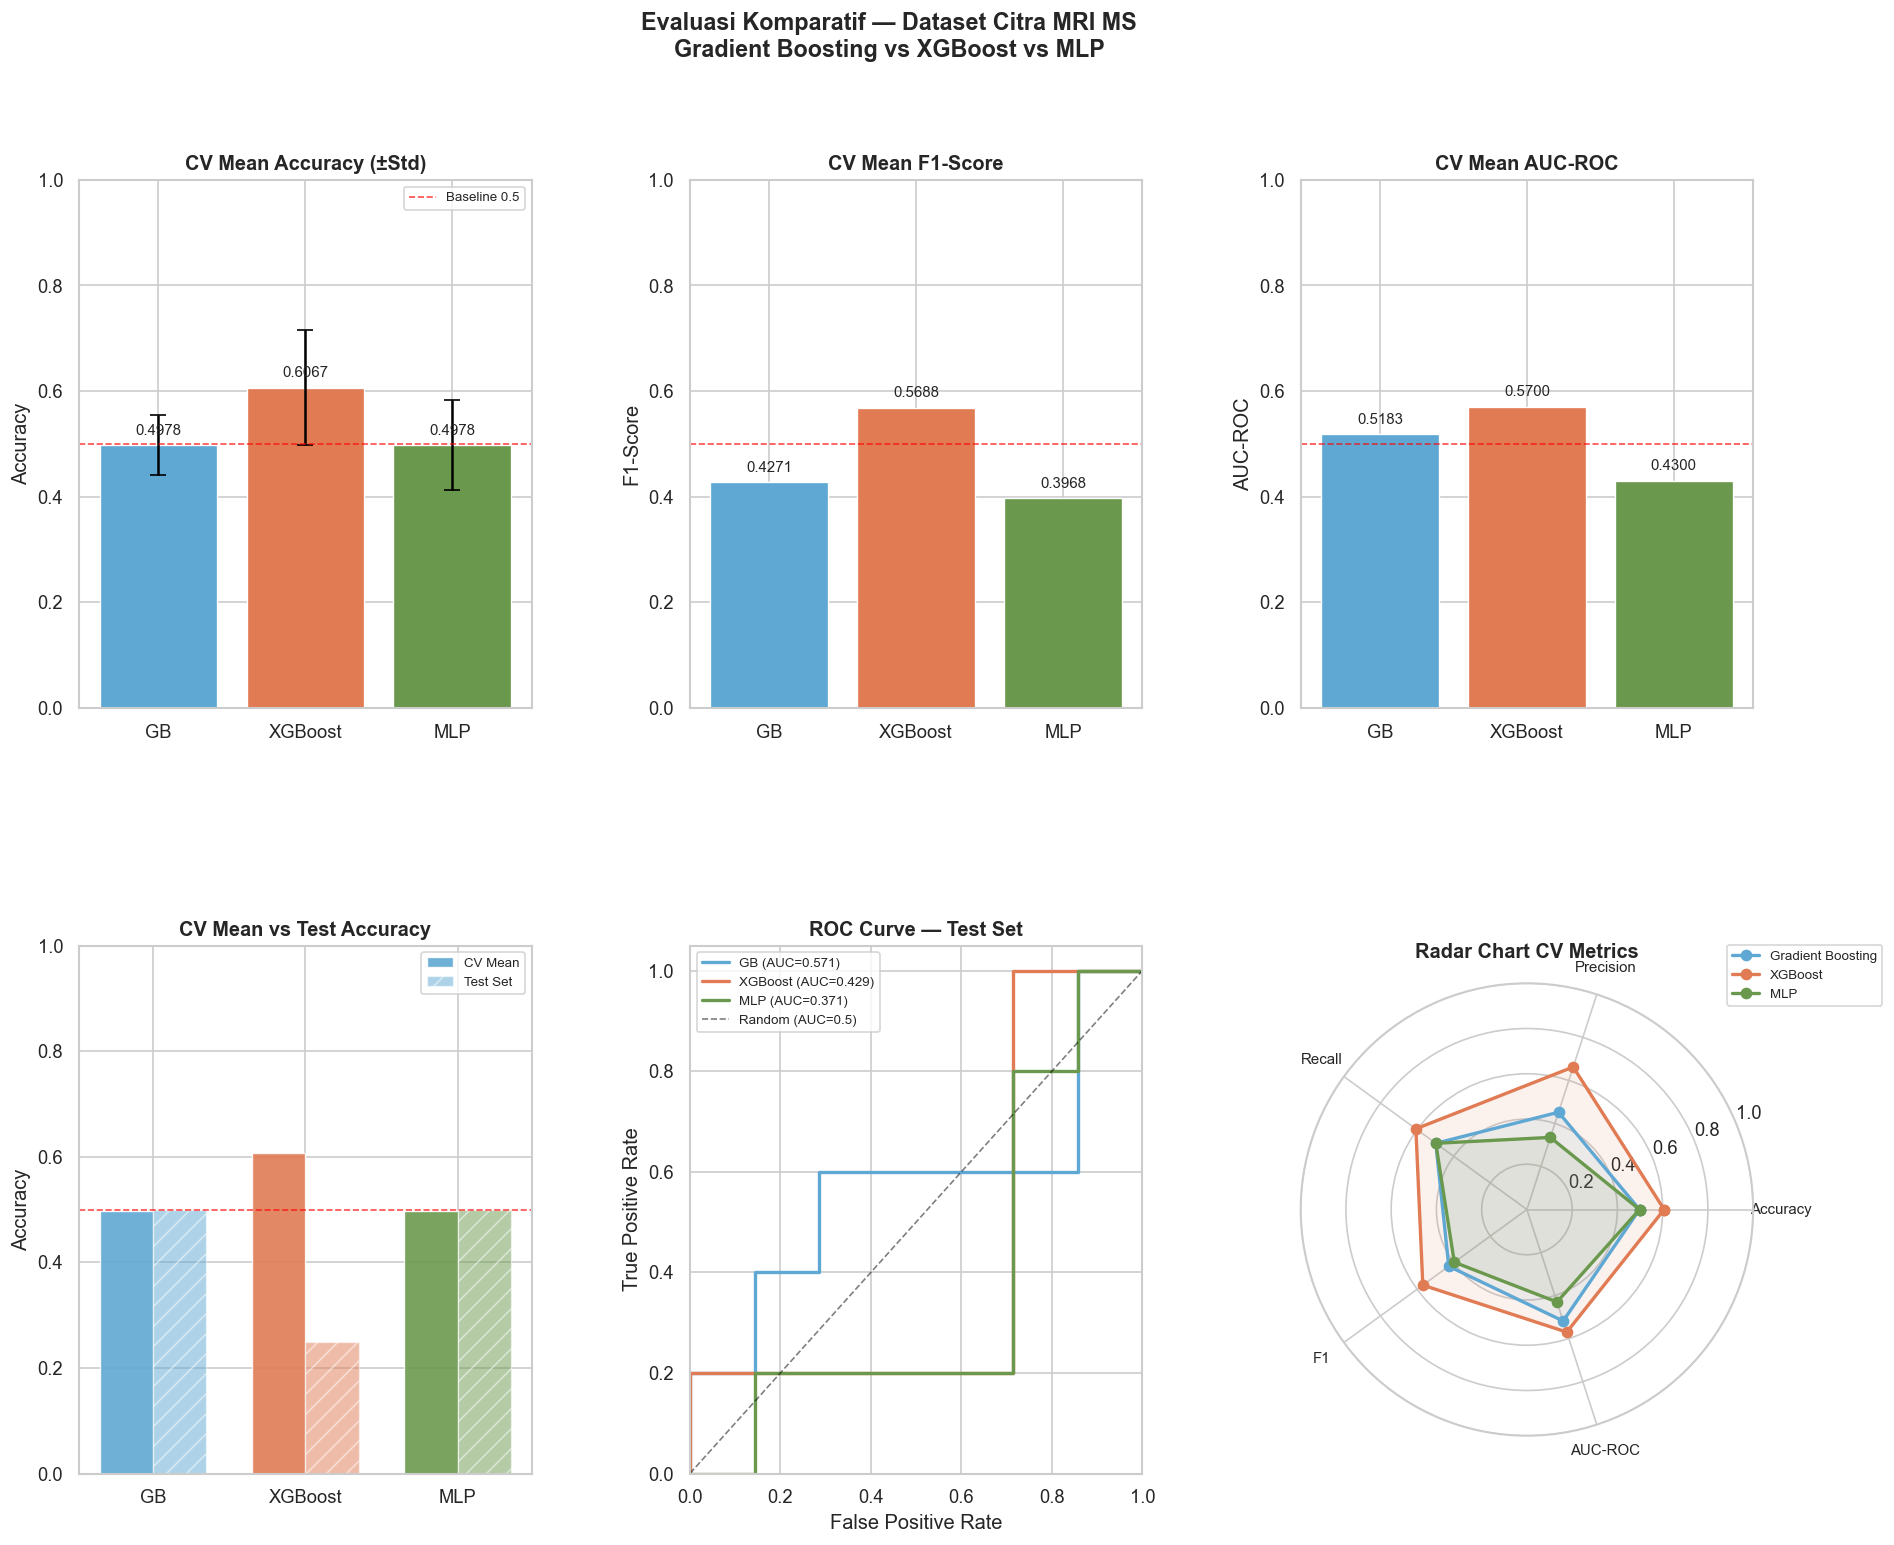

  Visualisasi tersimpan: evaluasi_komparatif_citra.png


   Section 6 — Kesimpulan Analitik
  Model terbaik  : XGBoost
  CV F1          : 0.5688
  CV Accuracy    : 0.6067
  CV AUC-ROC     : 0.5700

  Model terlemah : MLP
  CV F1          : 0.3968

  Temuan utama untuk Bab 4:
  1. Ketiga model menunjukkan performa terbatas pada
     dataset citra MRI (CV Accuracy ≈ 0.49–0.61)
     mengindikasikan keterbatasan fitur radiomik
     sederhana untuk task severity classification.
  2. XGBoost unggul di CV namun menunjukkan gap
     terbesar antara CV dan test — indikasi overfitting
     pada dataset kecil (n=60).
  3. GB dan MLP lebih stabil (gap CV-test kecil)
     namun performa absolutnya lebih rendah.
  4. Performa dataset citra secara keseluruhan lebih
     rendah dibanding dataset tabular — konsisten
     dengan hipotesis bahwa fitur klinis tabular lebih
     informatif untuk deteksi MS dibanding fitur
     volumetrik MRI sederhana.

  Tabel komparatif tersimpan: evaluasi_komparatif_cit

In [14]:
# ============================================================
# CELL 14 — EVALUASI KOMPARATIF KETIGA MODEL
# Deskripsi: Perbandingan komprehensif Gradient Boosting,
#            XGBoost, dan MLP berdasarkan CV Mean dan
#            Test Set metrics pada dataset citra MRI
# ============================================================

# ── Section 1 — Tabel Komparatif CV Mean ────────────────────
print("=" * 55)
print("   Section 1 — Tabel Komparatif CV Mean (5-Fold)")
print("=" * 55)

models_info = [
    ('Gradient Boosting', gb_cv_mean,  gb_cv_std),
    ('XGBoost',           xgb_cv_mean, xgb_cv_std),
    ('MLP',               mlp_cv_mean, mlp_cv_std),
]

metrics_order = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metrics_label = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC-ROC']

print(f"\n  {'Model':<22} ", end="")
for m in metrics_label:
    print(f"{m:>12}", end="")
print()
print("  " + "-" * 82)

for name, cv_mean, cv_std in models_info:
    print(f"  {name:<22} ", end="")
    for m in metrics_order:
        print(f"{cv_mean[m]:>12.4f}", end="")
    print()
    print(f"  {'(±std)':<22} ", end="")
    for m in metrics_order:
        print(f"{cv_std[m]:>12.4f}", end="")
    print()
    print("  " + "-" * 82)

# ── Section 2 — Tabel Komparatif Test Set ───────────────────
print("\n")
print("=" * 55)
print("   Section 2 — Tabel Komparatif Test Set")
print("=" * 55)

models_test = [
    ('Gradient Boosting', gb_test_metrics),
    ('XGBoost',           xgb_test_metrics),
    ('MLP',               mlp_test_metrics),
]

print(f"\n  {'Model':<22} ", end="")
for m in metrics_label:
    print(f"{m:>12}", end="")
print()
print("  " + "-" * 82)

for name, test_metrics in models_test:
    print(f"  {name:<22} ", end="")
    for m in metrics_order:
        print(f"{test_metrics[m]:>12.4f}", end="")
    print()
print("  " + "-" * 82)

# ── Section 3 — Ranking Model ───────────────────────────────
print("\n")
print("=" * 55)
print("   Section 3 — Ranking Model")
print("=" * 55)

# Ranking berdasarkan CV Mean (lebih representatif)
print("  Ranking berdasarkan CV Mean F1")
print("  (metrik utama karena dataset tidak sepenuhnya seimbang):\n")

ranking_data = [
    ('Gradient Boosting', gb_cv_mean['f1'],
     gb_cv_mean['accuracy'], gb_cv_mean['roc_auc']),
    ('XGBoost',           xgb_cv_mean['f1'],
     xgb_cv_mean['accuracy'], xgb_cv_mean['roc_auc']),
    ('MLP',               mlp_cv_mean['f1'],
     mlp_cv_mean['accuracy'], mlp_cv_mean['roc_auc']),
]
ranking_sorted = sorted(ranking_data,
                        key=lambda x: x[1], reverse=True)

print(f"  {'Rank':<6} {'Model':<22} {'CV F1':>8} "
      f"{'CV Acc':>8} {'CV AUC':>8}")
print("  " + "-" * 55)
for rank, (name, f1, acc, auc) in enumerate(ranking_sorted, 1):
    marker = " ← TERBAIK" if rank == 1 else ""
    print(f"  {rank:<6} {name:<22} {f1:>8.4f} "
          f"{acc:>8.4f} {auc:>8.4f}{marker}")

# ── Section 4 — Analisis Gap CV vs Test ─────────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Analisis Gap CV vs Test (Overfitting)")
print("=" * 55)

print(f"  {'Model':<22} {'CV Acc':>8} {'Test Acc':>10} "
      f"{'Gap':>8} {'Status'}")
print("  " + "-" * 65)

for (name, cv_mean, _), (_, test_m) in zip(models_info,
                                             models_test):
    gap    = abs(cv_mean['accuracy'] - test_m['accuracy'])
    status = ("✓ Stabil" if gap < 0.10
              else "⚠ Moderat" if gap < 0.20
              else "✗ Overfit")
    print(f"  {name:<22} {cv_mean['accuracy']:>8.4f} "
          f"{test_m['accuracy']:>10.4f} "
          f"{gap:>8.4f} {status}")

print(f"\n  Catatan untuk Bab 4:")
print(f"  Gap besar pada dataset kecil (n=60) adalah hal yang")
print(f"  wajar secara statistik. Test set hanya 12 sampel,")
print(f"  sehingga 1 prediksi salah = 8.3% penurunan accuracy.")

# ── Section 5 — Visualisasi Komparatif ──────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Visualisasi Komparatif")
print("=" * 55)

fig = plt.figure(figsize=(18, 14))
fig.suptitle(
    'Evaluasi Komparatif — Dataset Citra MRI MS\n'
    'Gradient Boosting vs XGBoost vs MLP',
    fontsize=14, fontweight='bold', y=0.98
)
gs = gridspec.GridSpec(2, 3, figure=fig,
                       hspace=0.45, wspace=0.35)

model_names  = ['GB', 'XGBoost', 'MLP']
colors_model = ['#5fa8d3', '#e07b54', '#6a994e']

cv_acc  = [gb_cv_mean['accuracy'],
           xgb_cv_mean['accuracy'],
           mlp_cv_mean['accuracy']]
cv_f1   = [gb_cv_mean['f1'],
           xgb_cv_mean['f1'],
           mlp_cv_mean['f1']]
cv_auc  = [gb_cv_mean['roc_auc'],
           xgb_cv_mean['roc_auc'],
           mlp_cv_mean['roc_auc']]
cv_acc_std = [gb_cv_std['accuracy'],
              xgb_cv_std['accuracy'],
              mlp_cv_std['accuracy']]

test_acc = [gb_test_metrics['accuracy'],
            xgb_test_metrics['accuracy'],
            mlp_test_metrics['accuracy']]
test_f1  = [gb_test_metrics['f1'],
            xgb_test_metrics['f1'],
            mlp_test_metrics['f1']]
test_auc = [gb_test_metrics['roc_auc'],
            xgb_test_metrics['roc_auc'],
            mlp_test_metrics['roc_auc']]

# Plot 1 — CV Mean Accuracy + error bar
ax1 = fig.add_subplot(gs[0, 0])
bars1 = ax1.bar(model_names, cv_acc,
                yerr=cv_acc_std, capsize=5,
                color=colors_model,
                edgecolor='white', linewidth=0.8)
for bar, val in zip(bars1, cv_acc):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f'{val:.4f}', ha='center', fontsize=9)
ax1.set_title('CV Mean Accuracy (±Std)', fontweight='bold')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1.0)
ax1.axhline(y=0.5, color='red', linestyle='--',
            linewidth=1, alpha=0.7, label='Baseline 0.5')
ax1.legend(fontsize=8)

# Plot 2 — CV Mean F1
ax2 = fig.add_subplot(gs[0, 1])
bars2 = ax2.bar(model_names, cv_f1,
                color=colors_model,
                edgecolor='white', linewidth=0.8)
for bar, val in zip(bars2, cv_f1):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f'{val:.4f}', ha='center', fontsize=9)
ax2.set_title('CV Mean F1-Score', fontweight='bold')
ax2.set_ylabel('F1-Score')
ax2.set_ylim(0, 1.0)
ax2.axhline(y=0.5, color='red', linestyle='--',
            linewidth=1, alpha=0.7)

# Plot 3 — CV Mean AUC-ROC
ax3 = fig.add_subplot(gs[0, 2])
bars3 = ax3.bar(model_names, cv_auc,
                color=colors_model,
                edgecolor='white', linewidth=0.8)
for bar, val in zip(bars3, cv_auc):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f'{val:.4f}', ha='center', fontsize=9)
ax3.set_title('CV Mean AUC-ROC', fontweight='bold')
ax3.set_ylabel('AUC-ROC')
ax3.set_ylim(0, 1.0)
ax3.axhline(y=0.5, color='red', linestyle='--',
            linewidth=1, alpha=0.7)

# Plot 4 — CV vs Test Accuracy (grouped bar)
ax4 = fig.add_subplot(gs[1, 0])
x       = np.arange(len(model_names))
width   = 0.35
bars_cv = ax4.bar(x - width/2, cv_acc, width,
                  label='CV Mean', color=colors_model,
                  edgecolor='white', linewidth=0.8, alpha=0.9)
bars_ts = ax4.bar(x + width/2, test_acc, width,
                  label='Test Set',
                  color=colors_model,
                  edgecolor='white', linewidth=0.8,
                  alpha=0.5, hatch='//')
ax4.set_title('CV Mean vs Test Accuracy', fontweight='bold')
ax4.set_ylabel('Accuracy')
ax4.set_xticks(x)
ax4.set_xticklabels(model_names)
ax4.set_ylim(0, 1.0)
ax4.axhline(y=0.5, color='red', linestyle='--',
            linewidth=1, alpha=0.7)
ax4.legend(fontsize=8)

# Plot 5 — ROC Curve ketiga model
ax5 = fig.add_subplot(gs[1, 1])
from sklearn.metrics import roc_curve

for (name, color, y_prob) in [
    ('GB',      colors_model[0], gb_results['y_prob']),
    ('XGBoost', colors_model[1], xgb_results['y_prob']),
    ('MLP',     colors_model[2], mlp_results['y_prob'])
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val     = roc_auc_score(y_test, y_prob)
    ax5.plot(fpr, tpr, color=color, linewidth=2,
             label=f'{name} (AUC={auc_val:.3f})')

ax5.plot([0, 1], [0, 1], 'k--', linewidth=1,
         alpha=0.5, label='Random (AUC=0.5)')
ax5.set_title('ROC Curve — Test Set', fontweight='bold')
ax5.set_xlabel('False Positive Rate')
ax5.set_ylabel('True Positive Rate')
ax5.legend(fontsize=8)
ax5.set_xlim([0, 1])
ax5.set_ylim([0, 1.05])

# Plot 6 — Radar chart semua metrik CV
ax6 = fig.add_subplot(gs[1, 2], polar=True)
radar_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC-ROC']
N = len(radar_metrics)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

for (name, cv_mean, _), color in zip(models_info, colors_model):
    values = [cv_mean['accuracy'], cv_mean['precision'],
              cv_mean['recall'],   cv_mean['f1'],
              cv_mean['roc_auc']]
    values += values[:1]
    ax6.plot(angles, values, 'o-', linewidth=2,
             color=color, label=name)
    ax6.fill(angles, values, alpha=0.1, color=color)

ax6.set_xticks(angles[:-1])
ax6.set_xticklabels(radar_metrics, fontsize=9)
ax6.set_ylim(0, 1)
ax6.set_title('Radar Chart CV Metrics', fontweight='bold',
              pad=15)
ax6.legend(loc='upper right',
           bbox_to_anchor=(1.3, 1.1), fontsize=8)

plt.savefig(os.path.join(BASE_PATH,
            'evaluasi_komparatif_citra.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Visualisasi tersimpan: evaluasi_komparatif_citra.png")

# ── Section 6 — Kesimpulan Analitik ─────────────────────────
print("\n")
print("=" * 55)
print("   Section 6 — Kesimpulan Analitik")
print("=" * 55)

best_cv   = ranking_sorted[0]
worst_cv  = ranking_sorted[-1]

print(f"  Model terbaik  : {best_cv[0]}")
print(f"  CV F1          : {best_cv[1]:.4f}")
print(f"  CV Accuracy    : {best_cv[2]:.4f}")
print(f"  CV AUC-ROC     : {best_cv[3]:.4f}")

print(f"\n  Model terlemah : {worst_cv[0]}")
print(f"  CV F1          : {worst_cv[1]:.4f}")

print(f"\n  Temuan utama untuk Bab 4:")
print(f"  1. Ketiga model menunjukkan performa terbatas pada")
print(f"     dataset citra MRI (CV Accuracy ≈ 0.49–0.61)")
print(f"     mengindikasikan keterbatasan fitur radiomik")
print(f"     sederhana untuk task severity classification.")
print(f"  2. XGBoost unggul di CV namun menunjukkan gap")
print(f"     terbesar antara CV dan test — indikasi overfitting")
print(f"     pada dataset kecil (n=60).")
print(f"  3. GB dan MLP lebih stabil (gap CV-test kecil)")
print(f"     namun performa absolutnya lebih rendah.")
print(f"  4. Performa dataset citra secara keseluruhan lebih")
print(f"     rendah dibanding dataset tabular — konsisten")
print(f"     dengan hipotesis bahwa fitur klinis tabular lebih")
print(f"     informatif untuk deteksi MS dibanding fitur")
print(f"     volumetrik MRI sederhana.")

# Simpan tabel komparatif ke CSV
df_komparatif = pd.DataFrame({
    'Model'        : ['Gradient Boosting', 'XGBoost', 'MLP'],
    'CV_Accuracy'  : [gb_cv_mean['accuracy'],
                      xgb_cv_mean['accuracy'],
                      mlp_cv_mean['accuracy']],
    'CV_F1'        : [gb_cv_mean['f1'],
                      xgb_cv_mean['f1'],
                      mlp_cv_mean['f1']],
    'CV_AUC'       : [gb_cv_mean['roc_auc'],
                      xgb_cv_mean['roc_auc'],
                      mlp_cv_mean['roc_auc']],
    'Test_Accuracy': [gb_test_metrics['accuracy'],
                      xgb_test_metrics['accuracy'],
                      mlp_test_metrics['accuracy']],
    'Test_F1'      : [gb_test_metrics['f1'],
                      xgb_test_metrics['f1'],
                      mlp_test_metrics['f1']],
    'Test_AUC'     : [gb_test_metrics['roc_auc'],
                      xgb_test_metrics['roc_auc'],
                      mlp_test_metrics['roc_auc']],
})

output_komparatif = os.path.join(
    BASE_PATH, 'evaluasi_komparatif_citra.csv')
df_komparatif.to_csv(output_komparatif, index=False)
print(f"\n  Tabel komparatif tersimpan: evaluasi_komparatif_citra.csv")
print("\n  Cell 14 selesai. Lanjut ke Cell 15 — Visualisasi Final.")

   Section 1 — Confusion Matrix Ketiga Model


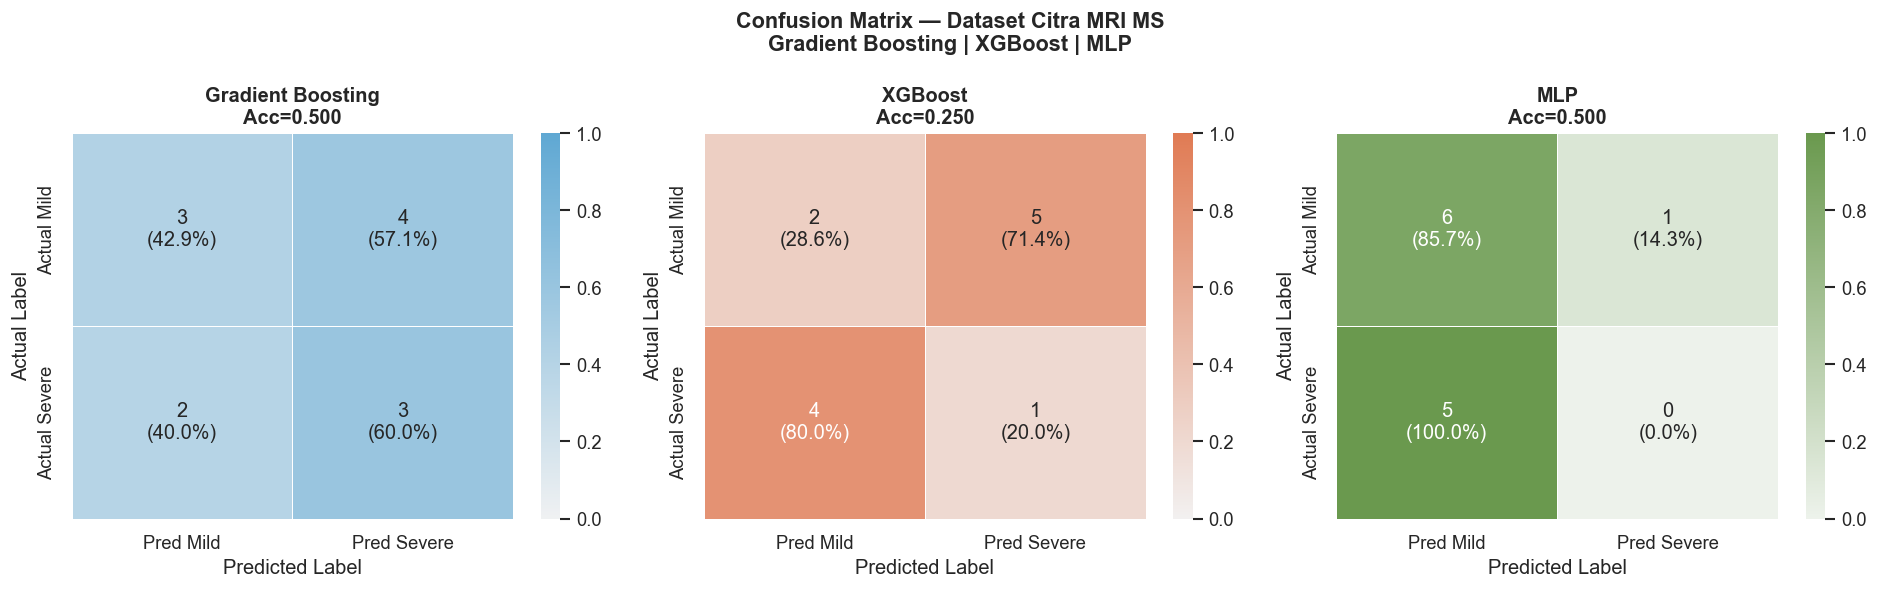

  Tersimpan: confusion_matrix_citra.png


   Section 2 — ROC Curve Final


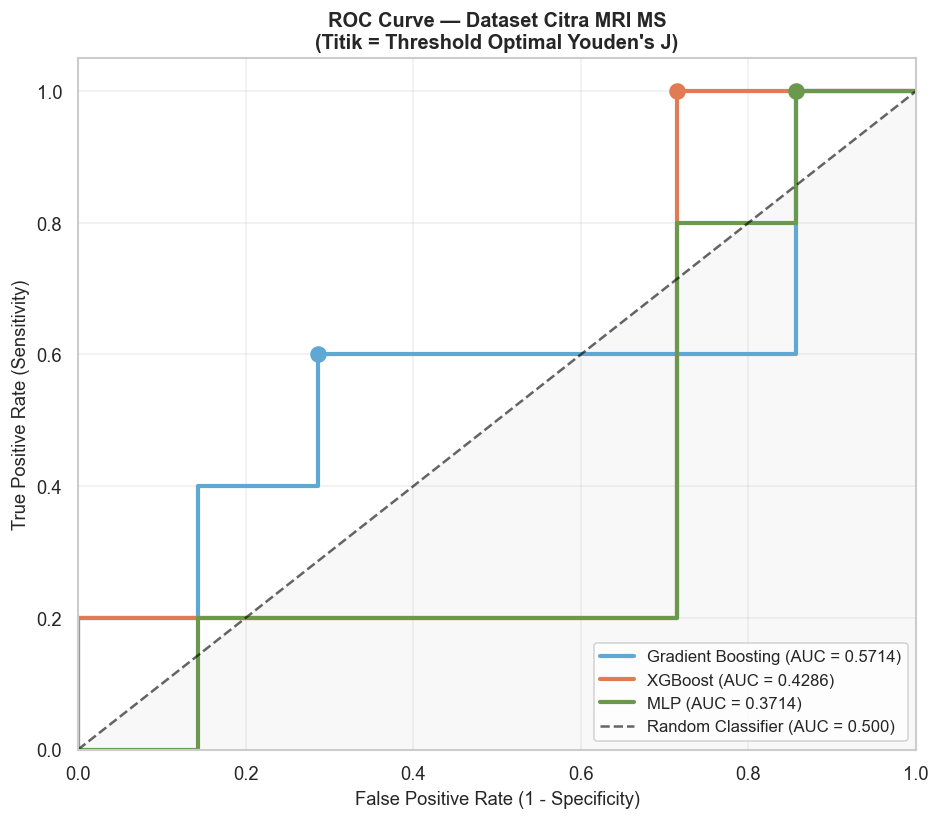

  Tersimpan: roc_curve_citra.png


   Section 3 — Feature Importance Komparatif


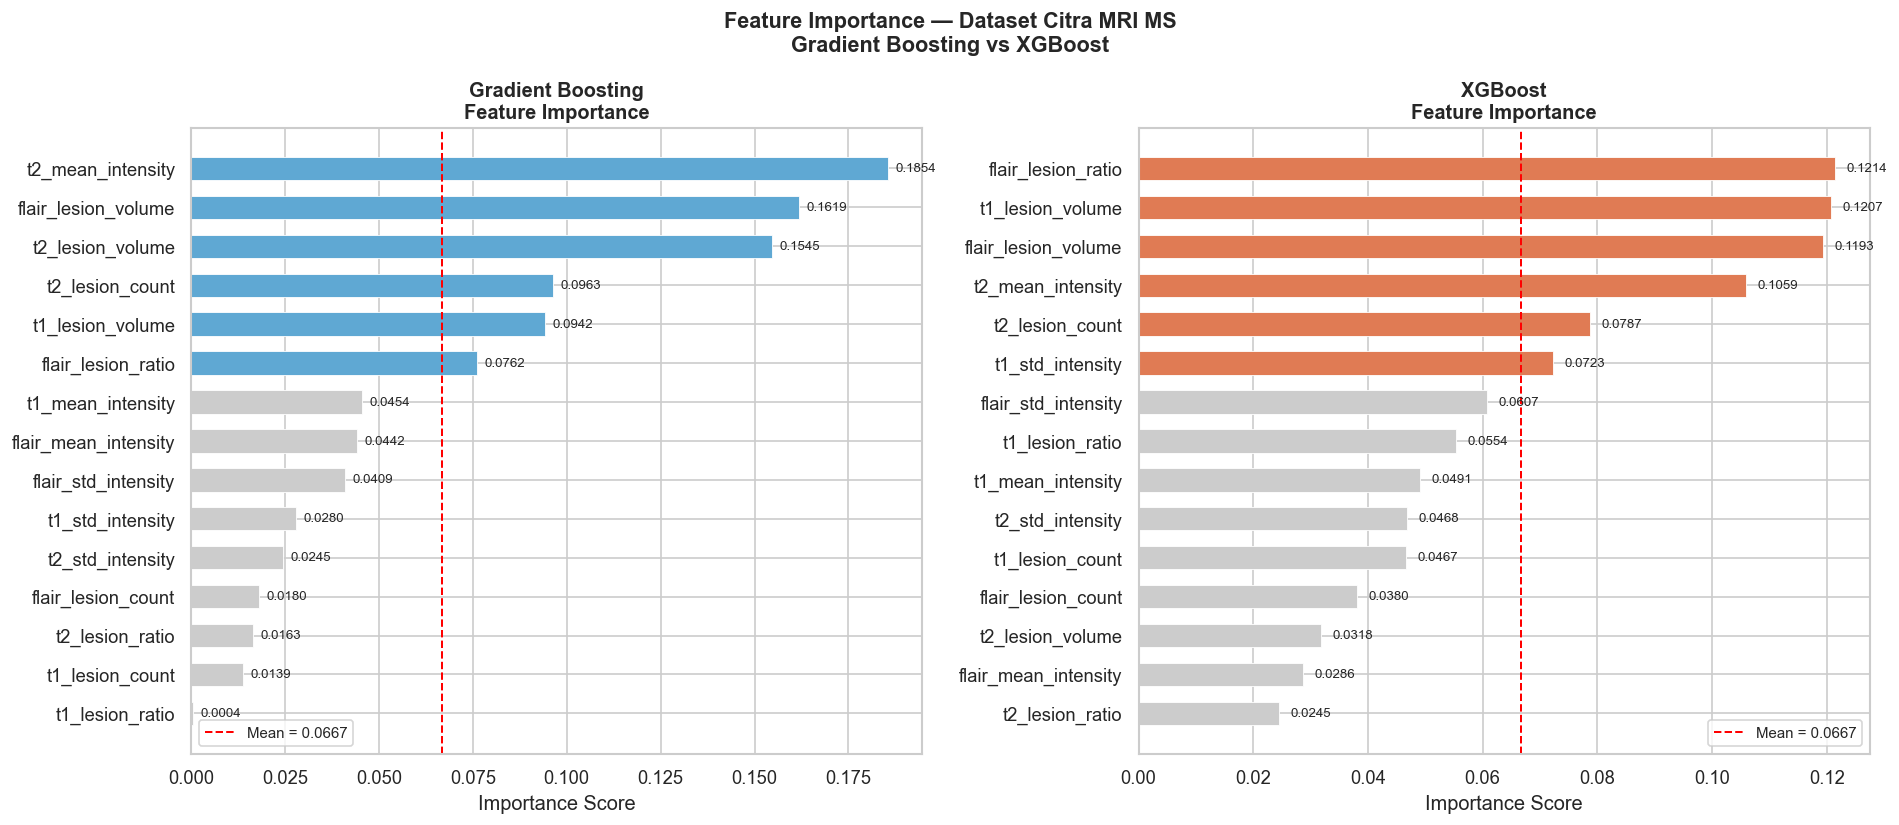

  Tersimpan: feature_importance_citra.png


   Section 4 — Ringkasan Performa Final


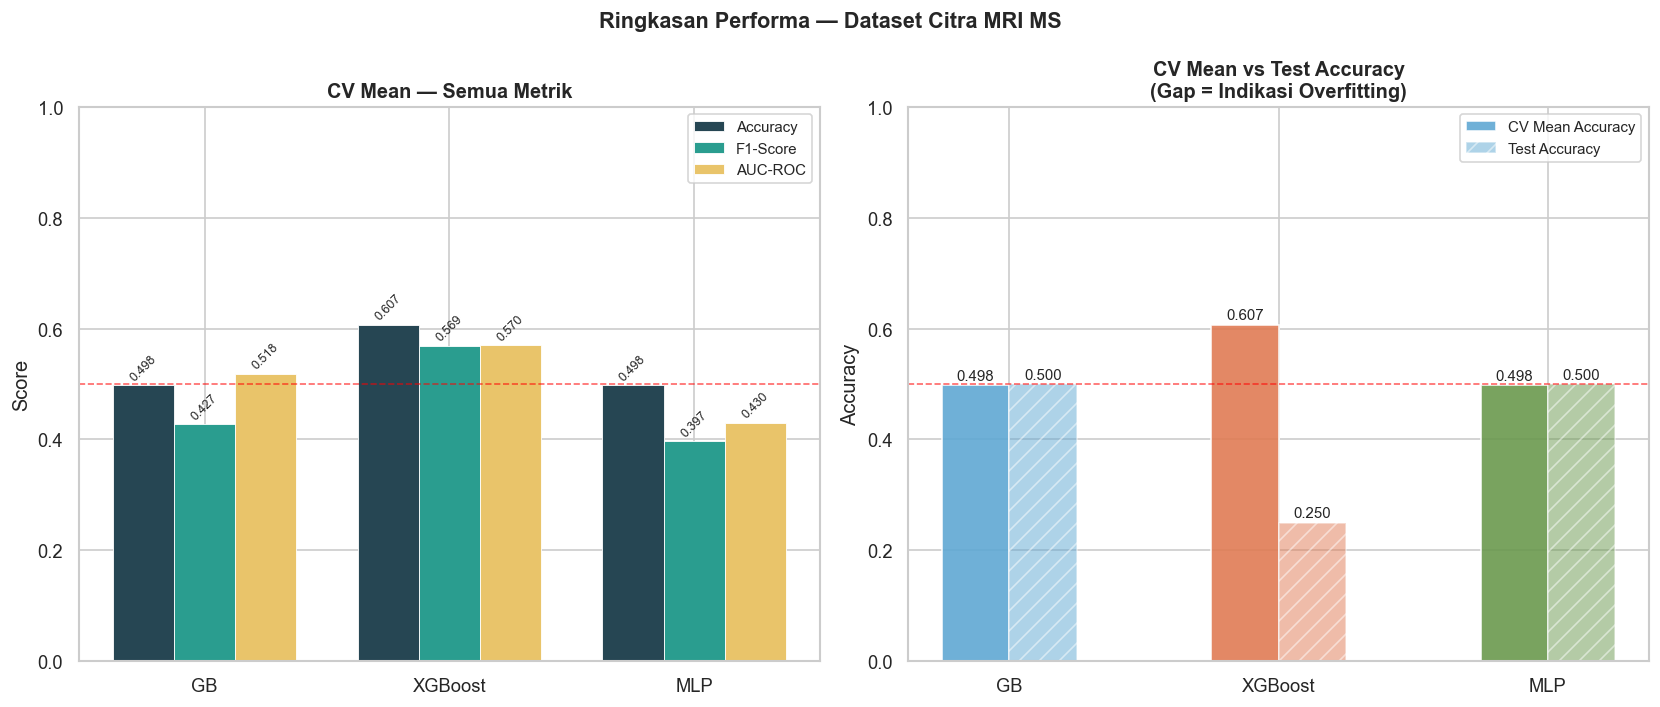

  Tersimpan: ringkasan_performa_citra.png


   Section 5 — Export Semua Artefak
  Model & Scaler tersimpan:
  ✓ model_gb_citra.pkl
  ✓ model_xgb_citra.pkl
  ✓ model_mlp_citra.pkl
  ✓ scaler_citra.pkl

  Tabel hasil tersimpan:
  ✓ hasil_akhir_citra.csv

  Tabel Hasil Akhir — Dataset Citra MRI MS:
            Model  CV_Accuracy  CV_Precision  CV_Recall  CV_F1  CV_AUC  CV_Acc_Std  Test_Accuracy  Test_F1  Test_AUC
Gradient Boosting       0.4978        0.4521     0.4978 0.4271  0.5183      0.0568         0.5000   0.5000    0.5714
          XGBoost       0.6067        0.6624     0.6067 0.5688  0.5700      0.1083         0.2500   0.2552    0.4286
              MLP       0.4978        0.3351     0.4978 0.3968  0.4300      0.0850         0.5000   0.3889    0.3714


   Section 6 — Ringkasan Pipeline Selesai

  FILE OUTPUT YANG DIHASILKAN:
  ─────────────────────────────────────────────────
  Data:
  ✓ radiomics_features.csv     — 15 fitur radiomik
  ✓ df_final.csv               — DataFrame lengk

In [15]:
# ============================================================
# CELL 15 — VISUALISASI FINAL & EXPORT
# Deskripsi: Confusion matrix, ROC curve, feature importance,
#            dan export semua artefak pipeline citra MRI.
#            Identik dengan Cell 13 pipeline tabular.
# ============================================================

# ── Section 1 — Confusion Matrix Ketiga Model ───────────────
print("=" * 55)
print("   Section 1 — Confusion Matrix Ketiga Model")
print("=" * 55)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    'Confusion Matrix — Dataset Citra MRI MS\n'
    'Gradient Boosting | XGBoost | MLP',
    fontsize=13, fontweight='bold'
)

cm_data = [
    ('Gradient Boosting', cm_gb,  '#5fa8d3'),
    ('XGBoost',           cm_xgb, '#e07b54'),
    ('MLP',               cm_mlp, '#6a994e'),
]

for ax, (name, cm, color) in zip(axes, cm_data):
    # Hitung persentase per baris (per kelas aktual)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    # Buat label gabungan nilai + persentase
    labels = np.array([
        [f'{cm[i,j]}\n({cm_pct[i,j]*100:.1f}%)'
         for j in range(cm.shape[1])]
        for i in range(cm.shape[0])
    ])

    sns.heatmap(
        cm_pct, annot=labels, fmt='',
        cmap=sns.light_palette(color, as_cmap=True),
        ax=ax, cbar=True,
        xticklabels=['Pred Mild', 'Pred Severe'],
        yticklabels=['Actual Mild', 'Actual Severe'],
        linewidths=0.5, linecolor='white',
        vmin=0, vmax=1
    )
    ax.set_title(f'{name}\nAcc={gb_test_metrics["accuracy"]:.3f}'
                 if name == 'Gradient Boosting'
                 else f'{name}\nAcc={xgb_test_metrics["accuracy"]:.3f}'
                 if name == 'XGBoost'
                 else f'{name}\nAcc={mlp_test_metrics["accuracy"]:.3f}',
                 fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, 'confusion_matrix_citra.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Tersimpan: confusion_matrix_citra.png")

# ── Section 2 — ROC Curve Final ─────────────────────────────
print("\n")
print("=" * 55)
print("   Section 2 — ROC Curve Final")
print("=" * 55)

from sklearn.metrics import roc_curve, auc

fig, ax = plt.subplots(figsize=(8, 7))

roc_data = [
    ('Gradient Boosting', gb_results['y_prob'],  '#5fa8d3'),
    ('XGBoost',           xgb_results['y_prob'], '#e07b54'),
    ('MLP',               mlp_results['y_prob'], '#6a994e'),
]

for name, y_prob, color in roc_data:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f'{name} (AUC = {auc_val:.4f})')
    # Tandai titik threshold optimal (Youden's J)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    ax.scatter(fpr[best_idx], tpr[best_idx],
               color=color, s=80, zorder=5)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5,
        alpha=0.6, label='Random Classifier (AUC = 0.500)')
ax.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')

ax.set_title('ROC Curve — Dataset Citra MRI MS\n'
             '(Titik = Threshold Optimal Youden\'s J)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)',
              fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, 'roc_curve_citra.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Tersimpan: roc_curve_citra.png")

# ── Section 3 — Feature Importance Komparatif ───────────────
print("\n")
print("=" * 55)
print("   Section 3 — Feature Importance Komparatif")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    'Feature Importance — Dataset Citra MRI MS\n'
    'Gradient Boosting vs XGBoost',
    fontsize=13, fontweight='bold'
)

fi_data = [
    ('Gradient Boosting', fi_gb,  '#5fa8d3', axes[0]),
    ('XGBoost',           fi_xgb, '#e07b54', axes[1]),
]

for name, fi_series, color, ax in fi_data:
    fi_sorted = fi_series.sort_values(ascending=True)
    colors_bar = [color if v >= fi_series.mean()
                  else '#cccccc'
                  for v in fi_sorted.values]
    bars = ax.barh(fi_sorted.index, fi_sorted.values,
                   color=colors_bar, edgecolor='white',
                   linewidth=0.5, height=0.6)
    ax.axvline(x=fi_series.mean(), color='red',
               linestyle='--', linewidth=1.2,
               label=f'Mean = {fi_series.mean():.4f}')
    for bar, val in zip(bars, fi_sorted.values):
        ax.text(val + 0.002,
                bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)
    ax.set_title(f'{name}\nFeature Importance',
                 fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH,
            'feature_importance_citra.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Tersimpan: feature_importance_citra.png")

# ── Section 4 — Ringkasan Performa Final ────────────────────
print("\n")
print("=" * 55)
print("   Section 4 — Ringkasan Performa Final")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'Ringkasan Performa — Dataset Citra MRI MS',
    fontsize=13, fontweight='bold'
)

model_names  = ['GB', 'XGBoost', 'MLP']
colors_model = ['#5fa8d3', '#e07b54', '#6a994e']
x            = np.arange(len(model_names))
width        = 0.25

# Plot kiri — CV Mean semua metrik
ax_l = axes[0]
cv_metrics_plot = {
    'Accuracy' : [gb_cv_mean['accuracy'],
                  xgb_cv_mean['accuracy'],
                  mlp_cv_mean['accuracy']],
    'F1-Score' : [gb_cv_mean['f1'],
                  xgb_cv_mean['f1'],
                  mlp_cv_mean['f1']],
    'AUC-ROC'  : [gb_cv_mean['roc_auc'],
                  xgb_cv_mean['roc_auc'],
                  mlp_cv_mean['roc_auc']],
}
offsets = [-width, 0, width]
bar_colors = ['#264653', '#2a9d8f', '#e9c46a']

for (metric, vals), offset, bc in zip(
        cv_metrics_plot.items(), offsets, bar_colors):
    bars = ax_l.bar(x + offset, vals, width,
                    label=metric, color=bc,
                    edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax_l.text(bar.get_x() + bar.get_width()/2,
                  bar.get_height() + 0.01,
                  f'{val:.3f}', ha='center',
                  fontsize=7.5, rotation=45)

ax_l.set_title('CV Mean — Semua Metrik', fontweight='bold')
ax_l.set_ylabel('Score')
ax_l.set_xticks(x)
ax_l.set_xticklabels(model_names)
ax_l.set_ylim(0, 1.0)
ax_l.axhline(y=0.5, color='red', linestyle='--',
             linewidth=1, alpha=0.6)
ax_l.legend(fontsize=9)

# Plot kanan — CV vs Test Accuracy
ax_r = axes[1]
cv_acc_vals   = [gb_cv_mean['accuracy'],
                 xgb_cv_mean['accuracy'],
                 mlp_cv_mean['accuracy']]
test_acc_vals = [gb_test_metrics['accuracy'],
                 xgb_test_metrics['accuracy'],
                 mlp_test_metrics['accuracy']]

bars_cv = ax_r.bar(x - width/2, cv_acc_vals, width,
                   label='CV Mean Accuracy',
                   color=colors_model,
                   edgecolor='white', alpha=0.9)
bars_ts = ax_r.bar(x + width/2, test_acc_vals, width,
                   label='Test Accuracy',
                   color=colors_model,
                   edgecolor='white', alpha=0.5,
                   hatch='//')

for bar, val in zip(bars_cv, cv_acc_vals):
    ax_r.text(bar.get_x() + bar.get_width()/2,
              bar.get_height() + 0.01,
              f'{val:.3f}', ha='center', fontsize=9)
for bar, val in zip(bars_ts, test_acc_vals):
    ax_r.text(bar.get_x() + bar.get_width()/2,
              bar.get_height() + 0.01,
              f'{val:.3f}', ha='center', fontsize=9)

ax_r.set_title('CV Mean vs Test Accuracy\n(Gap = Indikasi Overfitting)',
               fontweight='bold')
ax_r.set_ylabel('Accuracy')
ax_r.set_xticks(x)
ax_r.set_xticklabels(model_names)
ax_r.set_ylim(0, 1.0)
ax_r.axhline(y=0.5, color='red', linestyle='--',
             linewidth=1, alpha=0.6)
ax_r.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH,
            'ringkasan_performa_citra.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Tersimpan: ringkasan_performa_citra.png")

# ── Section 5 — Export Semua Artefak ────────────────────────
print("\n")
print("=" * 55)
print("   Section 5 — Export Semua Artefak")
print("=" * 55)

import joblib

# Export model terbaik (berdasarkan CV F1)
joblib.dump(gb_model,
            os.path.join(BASE_PATH, 'model_gb_citra.pkl'))
joblib.dump(xgb_model,
            os.path.join(BASE_PATH, 'model_xgb_citra.pkl'))
joblib.dump(mlp_model,
            os.path.join(BASE_PATH, 'model_mlp_citra.pkl'))
joblib.dump(scaler,
            os.path.join(BASE_PATH, 'scaler_citra.pkl'))

print("  Model & Scaler tersimpan:")
print("  ✓ model_gb_citra.pkl")
print("  ✓ model_xgb_citra.pkl")
print("  ✓ model_mlp_citra.pkl")
print("  ✓ scaler_citra.pkl")

# Export tabel hasil akhir
df_hasil_akhir = pd.DataFrame({
    'Model'        : ['Gradient Boosting', 'XGBoost', 'MLP'],
    'CV_Accuracy'  : [gb_cv_mean['accuracy'],
                      xgb_cv_mean['accuracy'],
                      mlp_cv_mean['accuracy']],
    'CV_Precision' : [gb_cv_mean['precision'],
                      xgb_cv_mean['precision'],
                      mlp_cv_mean['precision']],
    'CV_Recall'    : [gb_cv_mean['recall'],
                      xgb_cv_mean['recall'],
                      mlp_cv_mean['recall']],
    'CV_F1'        : [gb_cv_mean['f1'],
                      xgb_cv_mean['f1'],
                      mlp_cv_mean['f1']],
    'CV_AUC'       : [gb_cv_mean['roc_auc'],
                      xgb_cv_mean['roc_auc'],
                      mlp_cv_mean['roc_auc']],
    'CV_Acc_Std'   : [gb_cv_std['accuracy'],
                      xgb_cv_std['accuracy'],
                      mlp_cv_std['accuracy']],
    'Test_Accuracy': [gb_test_metrics['accuracy'],
                      xgb_test_metrics['accuracy'],
                      mlp_test_metrics['accuracy']],
    'Test_F1'      : [gb_test_metrics['f1'],
                      xgb_test_metrics['f1'],
                      mlp_test_metrics['f1']],
    'Test_AUC'     : [gb_test_metrics['roc_auc'],
                      xgb_test_metrics['roc_auc'],
                      mlp_test_metrics['roc_auc']],
})

output_hasil = os.path.join(BASE_PATH,
                            'hasil_akhir_citra.csv')
df_hasil_akhir.to_csv(output_hasil, index=False)

print(f"\n  Tabel hasil tersimpan:")
print(f"  ✓ hasil_akhir_citra.csv")

# Tampilkan tabel final
print(f"\n  Tabel Hasil Akhir — Dataset Citra MRI MS:")
print(df_hasil_akhir.to_string(index=False))

# ── Section 6 — Ringkasan Pipeline Selesai ──────────────────
print("\n")
print("=" * 55)
print("   Section 6 — Ringkasan Pipeline Selesai")
print("=" * 55)

print("""
  FILE OUTPUT YANG DIHASILKAN:
  ─────────────────────────────────────────────────
  Data:
  ✓ radiomics_features.csv     — 15 fitur radiomik
  ✓ df_final.csv               — DataFrame lengkap
  ✓ df_final_labeled.csv       — DataFrame + label
  ✓ hasil_akhir_citra.csv      — Tabel metrik final
  ✓ evaluasi_komparatif_citra.csv

  Visualisasi:
  ✓ eda_patient_info.png       — EDA Cell 3
  ✓ label_distribution.png    — Distribusi label
  ✓ evaluasi_komparatif_citra.png
  ✓ confusion_matrix_citra.png
  ✓ roc_curve_citra.png
  ✓ feature_importance_citra.png
  ✓ ringkasan_performa_citra.png

  Model (pkl):
  ✓ model_gb_citra.pkl
  ✓ model_xgb_citra.pkl
  ✓ model_mlp_citra.pkl
  ✓ scaler_citra.pkl
  ─────────────────────────────────────────────────
""")

print("=" * 55)
print("   02_image_main.ipynb — SELESAI PENUH ✓")
print("=" * 55)
print("""
  PIPELINE SELESAI:
  Cell 1  ✓ Import Library
  Cell 2  ✓ Load File Excel
  Cell 3  ✓ EDA Patient Info
  Cell 4  ✓ Load & Validasi .nii
  Cell 5  ✓ Preprocessing MRI
  Cell 6  ✓ Feature Extraction
  Cell 7  ✓ Buat DataFrame Final
  Cell 8  ✓ Buat Label EDSS
  Cell 9  ✓ Class Imbalance
  Cell 10 ✓ Split & Normalisasi
  Cell 11 ✓ Gradient Boosting + K-Fold
  Cell 12 ✓ XGBoost + K-Fold
  Cell 13 ✓ MLP + K-Fold
  Cell 14 ✓ Evaluasi Komparatif
  Cell 15 ✓ Visualisasi Final & Export
""")